# RAVE-VL v4 · Portion 3 — GPU escalation passes → offline policy evaluation → pre-registered tests → paper figures

**Inputs are restored from Google Drive** (`MyDrive/Koushik 2/rave_work/`, written by Portions 1–2), so this runs on a
fresh runtime; every output is mirrored back to Drive after every phase, and this notebook (with outputs) is saved to
`Koushik 2/notebooks/` at the end. A100 time continues from Portion 2 (summed executed cell time; downloads and
restores excluded). Every cell prints wall time, CPU time (kernel + workers), GPU busy time (CUDA events) and energy.

| Phase | Device | What |
|---|---|---|
| P3.0 | CPU | Load Portion 1/2 artefacts; **verify the pre-registration hash** (the escalation sets cannot have changed) |
| P3.A | GPU | Load the model; check exact token counts; reuse Portion 2's batch size and throughput |
| P3.B | GPU | **12 dense passes** over all questions (6 escalation variants × budgets 256 and 1,024), resumable, highest priority first, each skipped if it would not fit in the window |
| P3.C | CPU | Stage-4 merge: M1 replace, **M2 log-linear pooling (weight fitted out-of-fold)**, M3 more-confident |
| P3.D | CPU | Every gate × escalation rate, offline (no extra GPU): RAVE risk, **RAVE VoI** (fitted now, as pre-registered), LookWise-style, LazyMCoT-style, entropy, random, oracle |
| P3.E | CPU | Pre-registered hypotheses H1–H10 (paired bootstrap + exact McNemar, Holm on H1–H4) |
| P3.F | CPU | Main, ablation and gate tables as CSV + LaTeX (booktabs) |
| P3.G | CPU | **Paper figures**: accuracy–token frontier, effect forest plot, where crops help, compute & energy, qualitative examples, merge weight |

All dense passes run once; every policy and rate is then scored on the CPU with zero extra GPU time.

In [1]:
%pip install -q "transformers>=4.57.0" accelerate "datasets>=3.0" nvidia-ml-py psutil pandas pyarrow scikit-learn scipy tqdm packaging matplotlib

In [2]:
import os, sys, json, math, re, time, random, string, hashlib, zlib, warnings, shutil, tarfile
from pathlib import Path
import multiprocessing as mp
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def usable_cpus():
    """CPUs this process may really use (affinity + cgroup quota). os.cpu_count() inside a container often
    reports every host core, which oversubscribes threads and makes CPU work crawl."""
    n = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
    try:                                                            # cgroup v2
        q, p = open("/sys/fs/cgroup/cpu.max").read().split()[:2]
        if q != "max":
            n = min(n, max(1, int(q) // int(p)))
    except Exception:
        try:                                                        # cgroup v1
            q = int(open("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read())
            p = int(open("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read())
            if q > 0:
                n = min(n, max(1, q // p))
        except Exception:
            pass
    return max(1, n)

N_CPU = int(os.environ.get("RAVE_CPUS", usable_cpus()))
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(_v, str(N_CPU))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# fewer "out of memory" errors from fragmentation when batch shapes vary (must be set before torch is imported)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# ── Storage: fast local working copy + permanent copy in Google Drive ("Koushik 2") ─────────────
# Colab's /content disk is wiped whenever the runtime is recycled (new GPU, disconnect, restart of the VM), so
# every portion works on local disk for speed and mirrors everything to Drive after every phase. The next
# portion restores from Drive automatically, on any runtime.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DRIVE_FOLDER = os.environ.get("RAVE_DRIVE_FOLDER", "Koushik 2")
if os.environ.get("RAVE_DRIVE_ROOT"):                 # any folder can stand in for Drive (tests, other machines)
    DRIVE_ROOT = Path(os.environ["RAVE_DRIVE_ROOT"]) / DRIVE_FOLDER
elif IN_COLAB:
    DRIVE_HELP = """Google Drive did not mount ({err}).
How to fix it (most common cause first):
  1. Run this cell again. In the Google sign-in window pick the SAME account that runs this notebook and tick EVERY
     permission box (in particular "See, edit, create and delete all of your Google Drive files"), then Continue.
  2. Or: folder icon in Colab's left sidebar -> "Mount Drive" (mounts without the pop-up), then run this cell again.
  3. Still failing: Runtime -> Disconnect and delete runtime, allow pop-ups for colab.research.google.com, start again.
Nothing has been computed yet, so nothing is lost."""

    def _mount_drive():
        if os.path.isdir("/content/drive/MyDrive"):
            return
        from google.colab import drive
        err = None
        for kw in ({}, {"force_remount": True}):          # second try = a fresh sign-in window
            try:
                drive.mount("/content/drive", timeout_ms=300_000, **kw)
            except Exception as e:                       # e.g. "credential propagation was unsuccessful"
                err = e
                print(f"  Drive mount attempt failed: {type(e).__name__}: {e}")
            if os.path.isdir("/content/drive/MyDrive"):
                return
        raise RuntimeError(DRIVE_HELP.format(err=f"{type(err).__name__}: {err}" if err else "MyDrive not visible"))

    _mount_drive()
    DRIVE_ROOT = Path("/content/drive/MyDrive") / DRIVE_FOLDER
else:
    DRIVE_ROOT = None
if DRIVE_ROOT is not None:
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
DRIVE_WORK = DRIVE_ROOT / "rave_work" if DRIVE_ROOT is not None else None
WORK = Path(os.environ.get("RAVE_WORK", "/content/rave_work" if IN_COLAB else "./rave_work")).resolve()
DIRS = {k: WORK / k for k in ["raw", "global", "crops", "meta", "logs", "preds"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
HEAVY_DIRS = {"raw", "global", "crops"}               # thousands of images -> stored on Drive as one tar per dataset

def _walk_small(root):
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in HEAVY_DIRS]
        for f in filenames:
            if f == "images.tar" or f.endswith(".partial"):
                continue
            yield Path(dirpath) / f

import threading
_SYNC_LOCK = threading.Lock()
_SYNCED = {}                                           # local path -> (size, mtime_ns) already on Drive

def _key(st):
    return (st.st_size, st.st_mtime_ns)

def sync_to_drive(quiet=True):
    """Copy every new/changed small file (tables, predictions, logs, figures) from WORK to Drive.
    Files already copied are remembered, so Drive (slow to query) is only touched for real changes; each copy goes
    to '<name>.partial' first and is then renamed, so a runtime that dies mid-copy never leaves a broken file."""
    if DRIVE_WORK is None:
        return 0
    n = 0
    with _SYNC_LOCK:
        for p in _walk_small(WORK):
            try:
                st = p.stat()
                if _SYNCED.get(p) == _key(st):
                    continue
                q = DRIVE_WORK / p.relative_to(WORK)
                try:
                    qs = q.stat()
                    if qs.st_size == st.st_size and qs.st_mtime >= st.st_mtime - 2:
                        _SYNCED[p] = _key(st)
                        continue
                except FileNotFoundError:
                    pass
                q.parent.mkdir(parents=True, exist_ok=True)
                tmp = q.with_name(q.name + ".partial")
                shutil.copyfile(p, tmp)
                try:
                    shutil.copystat(p, tmp)                # keeps mtimes when the Drive mount allows it
                except OSError:
                    pass
                os.replace(tmp, q)
                _SYNCED[p] = _key(st)
                n += 1
            except OSError as e:                           # a Drive hiccup must never kill a GPU run
                print(f"  (Drive sync skipped {p.name}: {e})")
    if not quiet:
        print(f"Drive sync: {n} file(s) -> {DRIVE_WORK}")
    return n

def sync_in_background():
    """Non-blocking sync for use inside GPU loops (skipped if a sync is already running)."""
    if DRIVE_WORK is None or _SYNC_LOCK.locked():
        return
    threading.Thread(target=lambda: sync_to_drive(), daemon=True).start()

def archive_images_to_drive(sub=""):
    """Pack raw/, global/, crops/ of WORK/sub into one tar on Drive (thousands of small files are slow on Drive)."""
    if DRIVE_WORK is None:
        return
    base, dst = WORK / sub, DRIVE_WORK / sub / "images.tar"
    dst.parent.mkdir(parents=True, exist_ok=True)
    part = dst.with_name("images.tar.partial")
    with tarfile.open(part, "w") as tf:
        for d in sorted(HEAVY_DIRS):
            if (base / d).exists():
                tf.add(base / d, arcname=d)
    os.replace(part, dst)
    print(f"images archived -> {dst} ({dst.stat().st_size / 1e9:.2f} GB)")

def restore_from_drive(sub="", images=True):
    """Bring WORK/sub back from Drive on a fresh runtime: small files copied, images extracted from the tar."""
    if DRIVE_WORK is None:
        print("no Drive folder configured: using local files only"); return
    src = DRIVE_WORK / sub
    if not src.exists():
        print(f"nothing on Drive yet at {src}"); return
    n = 0
    for p in _walk_small(src):
        q = WORK / p.relative_to(DRIVE_WORK)
        if p.name == "time_ledger.jsonl" and q.exists():   # merge: Drive history + rows this runtime already wrote
            drive_text = p.read_text()
            seen = set(drive_text.splitlines())
            local_new = [l for l in q.read_text().splitlines() if l and l not in seen]
            q.write_text(drive_text + ("" if drive_text.endswith("\n") or not drive_text else "\n")
                         + "".join(l + "\n" for l in local_new))
            n += 1
            continue
        if not q.exists() or q.stat().st_size != p.stat().st_size:
            q.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p, q); n += 1
        _SYNCED[q] = _key(q.stat())                    # identical to Drive: the next sync skips it
    tar, gdir = src / "images.tar", WORK / sub / "global"
    extracted = False
    if images and tar.exists() and not (gdir.exists() and any(gdir.iterdir())):
        with tarfile.open(tar) as tf:
            try:
                tf.extractall(WORK / sub, filter="data")
            except TypeError:                          # Python < 3.12
                tf.extractall(WORK / sub)
        extracted = True
    print(f"restored {n} file(s) from {src}" + (" + images" if extracted else ""))

def save_notebook_copy(name):
    """Colab only: write this notebook WITH its outputs into Drive/<folder>/notebooks/."""
    if not IN_COLAB or DRIVE_ROOT is None:
        print("not running in Colab: save the notebook yourself"); return
    try:
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
        out = DRIVE_ROOT / "notebooks" / f"{name}_executed_{time.strftime('%Y%m%d_%H%M')}.ipynb"
        out.parent.mkdir(parents=True, exist_ok=True)
        out.write_text(json.dumps(nb))
        print("notebook with outputs ->", out)
    except Exception as e:
        print(f"could not save the notebook automatically ({e}); use File > Save a copy in Drive")

SEED = 20261017
random.seed(SEED)
SMOKE_N = int(os.environ.get("RAVE_SMOKE_N", "0"))       # 0 = full run (1,730 questions); >0 = quick test

DATASET, CONFIG = "MMMU/MMMU_Pro", "standard (10 options)"
MODEL_ID = os.environ.get("RAVE_MODEL_ID", "Qwen/Qwen3-VL-8B-Instruct")

# Qwen3-VL geometry: 16-px patches + 2x2 spatial merge -> 1 LLM visual token per 32x32 px.
FACTOR = 32
PX_PER_TOKEN = FACTOR * FACTOR
MIN_IMG_TOKENS = 64                      # Qwen3-VL default floor (shortest_edge = 65,536 px)
GLOBAL_BUDGETS = [128, 256, 512, 1024]   # Stage-1 visual tokens per QUESTION -> uniform-resolution frontier
NATIVE_CAP = 4096                        # "native" reference: only downscaled above 4,096 tokens per question
BASES = [str(b) for b in GLOBAL_BUDGETS] + ["native"]
MAIN_BASE = "256"                        # pre-registered Stage-1 budget (P1.3 prints the label-free reason)
PROTOCOL_BASE = "1024"                   # v1 protocol budget, kept as the secondary operating point
CROP_TOKENS_MIN, CROP_TOKENS_MAX = 256, 512   # one escalation crop; small regions are up-sampled (= the zoom)
LETTERS = string.ascii_uppercase         # MMMU-Pro standard(10) has 2-12 options (one question has 12)
PH = re.compile(r"<image (\d+)>")
INSTR = "Answer with the option's letter from the given choices directly."
PROMPT_VERSION = "v2-prefix-compatible"
print(f"WORK={WORK} | Drive={DRIVE_WORK} | usable CPUs={N_CPU} (os.cpu_count()={os.cpu_count()}) | "
      f"model={MODEL_ID} | SMOKE_N={SMOKE_N or 'full run'}")

import torch
NOTEBOOK = "P3"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
ON_GPU = DEVICE.startswith("cuda")
LOADER_WORKERS = min(8, max(1, N_CPU - 2))    # 8 keep an A100 busy; more only costs RAM
RISK_BASES = [MAIN_BASE, PROTOCOL_BASE]
ESC_KINDS = ["joint_top1", "b2_upscaled", "croponly_top1", "joint_rand", "b1_grid4", "joint_top3"]
P3_PASSES = [f"{k}@{b}" for b in RISK_BASES for k in ESC_KINDS]       # priority order: main budget first
GATE_NAMES = ["RAVE_risk", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy"]
MAIN_RATE = 0.3
ESC_RATES = [0.1, 0.2, 0.3, 0.4, 0.5]
RATE_GRID = [round(0.05 * i, 2) for i in range(21)]
W_GRID = [round(0.1 * i, 1) for i in range(11)]
SAFETY_MIN = 15                     # never start a pass that would end within 15 min of the 7-hour limit
N_BOOT = 5000

Mounted at /content/drive
WORK=/content/rave_work | Drive=/content/drive/MyDrive/Koushik 2/rave_work | usable CPUs=12 (os.cpu_count()=12) | model=Qwen/Qwen3-VL-8B-Instruct | SMOKE_N=full run


In [3]:
# ── CPU + GPU time ledger: EVERY executed cell and every named phase gets one row ─────────────
#  cpu_s        CPU-seconds of this kernel + its worker processes (Pool / DataLoader workers)
#  cores_used   cpu_s / wall_s   (how many cores the step really kept busy)
#  gpu_busy_s   phase rows: sum of CUDA-event-timed forward passes (exact)
#               cell rows : integral of NVML GPU utilisation, sampled every 0.25 s (approximate)
#               0.00 + "none" when no GPU is used (e.g. the whole of Portion 1)
#  gpu_energy_J NVML board-energy counter difference (supported on A100)
import time, json, resource, threading, datetime as dt
import psutil

LEDGER = DIRS["logs"] / "time_ledger.jsonl"
WINDOW_FILE = DIRS["logs"] / "a100_window.json"
WINDOW_H = 7.0

def _nvml():
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import pynvml                        # provided by nvidia-ml-py
        pynvml.nvmlInit()
        cvd = os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0].strip()
        h = pynvml.nvmlDeviceGetHandleByIndex(int(cvd) if cvd.isdigit() else 0)
        name = pynvml.nvmlDeviceGetName(h)
        return pynvml, h, (name.decode() if isinstance(name, bytes) else name)
    except Exception:
        return None, None, None
NV, NVH, GPU_NAME = _nvml()

def _energy_mJ():
    if NVH is None:
        return None
    try:
        return NV.nvmlDeviceGetTotalEnergyConsumption(NVH)
    except Exception:
        return None

def _torch_cuda():
    t = sys.modules.get("torch")
    try:
        return t if (t is not None and t.cuda.is_available() and t.cuda.is_initialized()) else None
    except Exception:
        return None

def _reaped_child_cpu():
    r = resource.getrusage(resource.RUSAGE_CHILDREN)
    return r.ru_utime + r.ru_stime

def _alive_children():
    out = {}
    try:
        for c in psutil.Process().children(recursive=True):
            try:
                t = c.cpu_times(); out[c.pid] = t.user + t.system
            except psutil.Error:
                pass
    except psutil.Error:
        pass
    return out

GPU_NOTEBOOKS = {"P2", "P3", "P4"}

def _ledger_window_s():
    s = 0.0
    if LEDGER.exists():
        with open(LEDGER) as f:
            for line in f:
                try:
                    r = json.loads(line)
                except ValueError:
                    continue
                if r.get("kind") == "cell" and r.get("notebook") in GPU_NOTEBOOKS and r.get("counts_to_window", True):
                    s += float(r.get("wall_s") or 0)
    return s

def window_used_h():
    """A100 hours used = executed cell time of all GPU portions (P2-P4), summed across runtimes (the ledger lives
    on Drive). Weight downloads are excluded. Idle time between cells is not counted."""
    if globals().get("NOTEBOOK") not in GPU_NOTEBOOKS:
        return None
    s = _ledger_window_s()
    ct = globals().get("CELL_TIMER")
    if ct is not None and ct.m is not None and getattr(ct, "counts", True):
        s += time.perf_counter() - ct.m.t0
    return round(s / 3600, 3)

def window(tag=""):
    used = window_used_h()
    if used is None:
        print(f"⏱ A100 time {tag}: not counted in this portion"); return
    print(f"⏱ A100 time {tag}: {used:.2f} h used, {WINDOW_H - used:.2f} h left of {WINDOW_H:.0f} h (P2–P4 cells)")
    if used > WINDOW_H:
        print("  ⚠ 7-hour budget exceeded")

class _Sampler(threading.Thread):
    def __init__(self, period=0.25):
        super().__init__(daemon=True)
        self.period, self.cpu, self.gpu, self.mem, self.ram = period, [], [], [], []
        self._halt = threading.Event()
    def run(self):
        while not self._halt.wait(self.period):
            self.cpu.append(psutil.cpu_percent(None))
            self.ram.append(psutil.virtual_memory().used / 1e9)
            if NVH is not None:
                try:
                    self.gpu.append(NV.nvmlDeviceGetUtilizationRates(NVH).gpu)
                    self.mem.append(NV.nvmlDeviceGetMemoryInfo(NVH).used / 1e9)
                except Exception:
                    pass
    def stop(self):
        self._halt.set(); self.join(timeout=2)
        return self

class _Meter:
    """Start/stop meter shared by Phase (named steps) and the automatic per-cell timer."""
    def start(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize(); tc.cuda.reset_peak_memory_stats()
        self.started = dt.datetime.now().isoformat(timespec="seconds")
        self.kids0 = _alive_children()
        self.t0, self.c0, self.k0, self.e0 = time.perf_counter(), time.process_time(), _reaped_child_cpu(), _energy_mJ()
        self.s = _Sampler(); self.s.start()
        return self
    def stop(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize()
        wall = time.perf_counter() - self.t0
        cpu_self = time.process_time() - self.c0
        kids1 = _alive_children()
        reaped = _reaped_child_cpu() - self.k0 - sum(v for p, v in self.kids0.items() if p not in kids1)
        alive = sum(v - self.kids0.get(p, 0.0) for p, v in kids1.items())
        cpu_child = max(0.0, reaped) + max(0.0, alive)
        s = self.s.stop(); e1 = _energy_mJ()
        mean = lambda xs: round(sum(xs) / len(xs), 1) if xs else None
        return dict(started=self.started, wall_s=round(wall, 3), cpu_s=round(cpu_self + cpu_child, 3),
                    cpu_self_s=round(cpu_self, 3), cpu_child_s=round(cpu_child, 3),
                    cores_used=round((cpu_self + cpu_child) / max(wall, 1e-9), 2), sys_cpu_util_pct=mean(s.cpu),
                    gpu_present=(NVH is not None) or (tc is not None), gpu_name=GPU_NAME,
                    gpu_util_pct=mean(s.gpu),
                    gpu_active_s=round(sum(s.gpu) / 100 * s.period, 3) if s.gpu else 0.0,
                    gpu_energy_J=round((e1 - self.e0) / 1000, 1) if (e1 is not None and self.e0 is not None) else None,
                    gpu_mem_used_gb_max=round(max(s.mem), 2) if s.mem else None,
                    gpu_peak_alloc_gb=round(tc.cuda.max_memory_allocated() / 1e9, 2) if tc is not None else None,
                    ram_used_gb_max=round(max(s.ram), 1) if s.ram else round(psutil.virtual_memory().used / 1e9, 1),
                    window_h_used=window_used_h())

def _write(row):
    with open(LEDGER, "a") as f:
        f.write(json.dumps(row, default=str) + "\n")

def _fmt(r):
    if r["gpu_busy_src"] == "none":
        g = "GPU 0.00 s (no GPU used)"
    else:
        g = f"GPU busy {r['gpu_busy_s']:.2f} s [{r['gpu_busy_src']}]"
        if r.get("gpu_util_pct") is not None:
            g += f", util {r['gpu_util_pct']}%"
        if r.get("gpu_energy_J"):
            g += f", {r['gpu_energy_J'] / 1000:.2f} kJ"
        if r.get("gpu_peak_alloc_gb"):
            g += f", peak {r['gpu_peak_alloc_gb']} GB"
    w = f" | A100 time {r['window_h_used']:.2f}/{WINDOW_H:.0f} h" if r.get("window_h_used") is not None else ""
    ram = f" | RAM peak {r['ram_used_gb_max']:.0f} GB" if r.get("ram_used_gb_max") is not None else ""
    return (f"⏱ {r['name']} | wall {r['wall_s']:.2f} s | CPU {r['cpu_s']:.2f} s ({r['cores_used']} cores, "
            f"sys {r['sys_cpu_util_pct']}%) | {g}{ram}{w}" + ("" if r["ok"] else "  ** FAILED **"))

class _GpuTimer:
    """Exact device time of one forward pass (CUDA events; perf_counter if the model runs on CPU)."""
    def __init__(self, phase=None):
        self.phase, self.s = phase, 0.0
    def __enter__(self):
        tc = _torch_cuda(); self.cuda = tc is not None
        if self.cuda:
            self.e0, self.e1 = tc.cuda.Event(enable_timing=True), tc.cuda.Event(enable_timing=True); self.e0.record()
        else:
            self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        if self.cuda:
            self.e1.record(); self.e1.synchronize(); self.s = self.e0.elapsed_time(self.e1) / 1000
        else:
            self.s = time.perf_counter() - self.t0
        if self.phase is not None:
            self.phase.gpu_busy_s += self.s; self.phase.n_dev_calls += 1
            self.phase.dev_src = "cuda_events" if self.cuda else "cpu_device_forward"
        return False

class Phase:
    """with Phase("P2.B B0", budget_min=10) as ph: ...  -> one 'phase' row (wall, CPU, GPU, energy).
    Wrap each forward pass in `with ph.gpu():` to add its exact CUDA-event time to gpu_busy_s."""
    def __init__(self, name, budget_min=None):
        self.name, self.budget_min, self.extra = name, budget_min, {}
        self.gpu_busy_s, self.n_dev_calls, self.dev_src, self.row = 0.0, 0, None, None
    def gpu(self):
        return _GpuTimer(self)
    def __enter__(self):
        self.m = _Meter().start(); return self
    def __exit__(self, et, ev, tb):
        r = self.m.stop()
        if self.n_dev_calls:
            busy, src = self.gpu_busy_s, self.dev_src
        elif r["gpu_active_s"] > 0:
            busy, src = r["gpu_active_s"], "nvml_util"
        else:
            busy, src = 0.0, ("none" if not r["gpu_present"] or not r["gpu_util_pct"] else "nvml_util")
        self.row = dict(kind="phase", notebook=NOTEBOOK, name=self.name, ok=et is None, **r,
                        gpu_busy_s=round(busy, 3), gpu_busy_src=src, n_forward=self.n_dev_calls,
                        budget_min=self.budget_min, **self.extra)
        _write(self.row); print(_fmt(self.row))
        if self.budget_min and r["wall_s"] > 60 * self.budget_min:
            print(f"  ⚠ over budget: {r['wall_s'] / 60:.1f} min > {self.budget_min} min")
        try:
            sync_in_background()                       # every finished phase goes to Drive (without blocking)
        except Exception as e:
            print(f"  (Drive sync failed: {e})")
        return False

class _CellTimer:
    def __init__(self):
        self.m, self.n, self.counts, self.last_sync = None, 0, True, time.time()
    def pre(self, info=None):
        raw = (getattr(info, "raw_cell", "") or "").strip()
        self.label = raw.splitlines()[0][:60] if raw else ""
        self.counts = "[no-window]" not in self.label           # e.g. weight downloads are not A100 time
        self.m = _Meter().start()
    def post(self, result=None):
        if self.m is None:
            return
        r = self.m.stop()
        self.m = None
        self.n += 1
        src = "nvml_util" if r["gpu_util_pct"] is not None else "none"
        row = dict(kind="cell", notebook=NOTEBOOK, name=f"cell {self.n}: {self.label}",
                   ok=bool(getattr(result, "success", True)), **r, counts_to_window=self.counts,
                   gpu_busy_s=r["gpu_active_s"] if src != "none" else 0.0, gpu_busy_src=src)
        _write(row); print(_fmt(row))
        if time.time() - self.last_sync > 20:
            try:
                sync_in_background(); self.last_sync = time.time()
            except Exception as e:
                print(f"  (Drive sync failed: {e})")

def _register_cell_timer():
    try:
        ip = get_ipython()                       # noqa: F821  (exists inside Jupyter)
    except NameError:
        return None
    old = getattr(ip, "_rave_cell_timer", None)
    if old is not None:
        for ev, fn in (("pre_run_cell", old.pre), ("post_run_cell", old.post)):
            try:
                ip.events.unregister(ev, fn)
            except ValueError:
                pass
    t = _CellTimer()
    ip.events.register("pre_run_cell", t.pre)
    ip.events.register("post_run_cell", t.post)
    ip._rave_cell_timer = t
    t.label = "(timer setup cell)"
    t.m = _Meter().start()                       # so this very cell is logged too
    return t

def time_report(notebook=None, save=True):
    """Totals (from per-cell rows = everything executed) + per-phase CPU/GPU table."""
    import pandas as pd
    if not LEDGER.exists():
        print("ledger empty"); return None
    df = pd.read_json(LEDGER, lines=True)
    if notebook:
        df = df[df.notebook == notebook]
    ce, ph = df[df.kind == "cell"], df[df.kind == "phase"].copy()
    en = ce["gpu_energy_J"].fillna(0).sum() if "gpu_energy_J" in ce else 0.0
    gpu_ph = ph[ph.gpu_busy_src.isin(["cuda_events", "nvml_util"])].gpu_busy_s.sum() if len(ph) else 0.0
    cpu_dev = ph[ph.gpu_busy_src == "cpu_device_forward"].gpu_busy_s.sum() if len(ph) else 0.0
    print(f"[{notebook or 'all notebooks'}] {len(ce)} cells | wall {ce.wall_s.sum() / 60:.1f} min | "
          f"CPU {ce.cpu_s.sum() / 60:.1f} CPU-min ({ce.cpu_s.sum() / max(ce.wall_s.sum(), 1e-9):.1f} cores avg) | "
          f"GPU busy {gpu_ph / 60:.2f} min (phases) / {ce.gpu_busy_s.sum() / 60:.2f} min (cells, NVML) | "
          f"GPU energy {en / 1000:.1f} kJ" + (f" | model forward on CPU (no GPU) {cpu_dev / 60:.2f} min" if cpu_dev else "") +
          (f" | A100 time used (P2–P4) {window_used_h():.2f} h of {WINDOW_H:.0f}" if window_used_h() is not None else ""))
    cols = ["name", "ok", "wall_s", "cpu_s", "cores_used", "sys_cpu_util_pct", "gpu_busy_s", "gpu_busy_src",
            "gpu_util_pct", "gpu_energy_J", "gpu_peak_alloc_gb", "ram_used_gb_max", "n_forward", "budget_min",
            "window_h_used"]
    ph = ph[[c for c in cols if c in ph]].reset_index(drop=True)
    if save:
        ph.to_csv(DIRS["logs"] / f"time_phases_{notebook or 'all'}.csv", index=False)
    return ph

CELL_TIMER = _register_cell_timer()
print("per-cell CPU/GPU timer:", "ON" if CELL_TIMER else "off (not in Jupyter)",
      "| GPU visible:", GPU_NAME or "none", "| ledger:", LEDGER)

per-cell CPU/GPU timer: ON | GPU visible: NVIDIA A100-SXM4-40GB | ledger: /content/rave_work/logs/time_ledger.jsonl
⏱ cell 1: (timer setup cell) | wall 0.01 s | CPU 0.01 s (1.01 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.00/7 h


In [4]:
# [no-window] restore Portions 1-2 from Drive (works on a fresh runtime) + fetch the model weights
restore_from_drive()
assert (DIRS["logs"] / "preregistration.json").exists(), (
    f"Portion 2 outputs not found in {DRIVE_WORK} — run Portion 2 v4 first (it saves everything to Drive)")
from huggingface_hub import snapshot_download
with Phase(f"P3.download {MODEL_ID} (network, not A100 time)", budget_min=15):
    snapshot_download(MODEL_ID, max_workers=16)
window("start of Portion 3 (continues from Portion 2)")

restored 53 file(s) from /content/drive/MyDrive/Koushik 2/rave_work + images


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

⏱ P3.download Qwen/Qwen3-VL-8B-Instruct (network, not A100 time) | wall 51.53 s | CPU 103.41 s (2.01 cores, sys 24.1%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.12/7 h
⏱ A100 time start of Portion 3 (continues from Portion 2): 0.12 h used, 6.88 h left of 7 h (P2–P4 cells)
⏱ cell 2: # [no-window] restore Portions 1-2 from Drive (works on a fr | wall 102.06 s | CPU 115.33 s (1.13 cores, sys 22.1%) | GPU busy 0.00 s [nvml_util], util 0.0%, 4.63 kJ | RAM peak 8 GB | A100 time 0.12/7 h


In [5]:
# ── Statistics used for every claim (paired, per-question) ────────────────────────────────────
import numpy as np

def boot_ci(x, n=5000, seed=SEED):
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    m = np.array([x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)])
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def paired_boot(a, b, n=5000, seed=SEED):
    """mean(a - b), 95% CI, one-sided bootstrap p-value for H0: mean(a - b) <= 0."""
    d = np.asarray(a, float) - np.asarray(b, float); rng = np.random.default_rng(seed)
    m = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5)), float((m <= 0).mean())

def mcnemar_exact(a_correct, b_correct):
    from scipy.stats import binomtest
    a, b = np.asarray(a_correct, bool), np.asarray(b_correct, bool)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
    return n10, n01, float(p)

def holm(pvals, alpha=0.05):
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); out, stop = {}, False
    for i, (k, p) in enumerate(items):
        stop = stop or p > alpha / (m - i)
        out[k] = dict(p=p, p_holm=min(1.0, max(p * (m - j) for j, (_, p) in enumerate(items[:i + 1]))), reject=not stop)
    return out

def ece(y, p, bins=15):
    y, p = np.asarray(y, float), np.asarray(p, float)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    return float(sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean()
                     for b in range(bins) if (idx == b).any()))

def aurc(err, risk):
    """Area under the risk-coverage curve: accept most-confident first; lower is better."""
    o = np.argsort(risk, kind="stable"); e = np.asarray(err, float)[o]
    return float((np.cumsum(e) / np.arange(1, len(e) + 1)).mean())

def boot_ci_fast(x, n=2000, seed=SEED):
    """Bootstrap CI for a mean using a multinomial weight matrix (fast, memory-light)."""
    x = np.asarray(x, float)
    if len(x) < 2:
        return float(x.mean()) if len(x) else float("nan"), float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    w = rng.multinomial(len(x), np.full(len(x), 1 / len(x)), size=n) / len(x)
    m = w @ x
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def tex(s):
    return str(s).replace("\\", "/").replace("_", r"\_").replace("%", r"\%").replace("&", r"\&").replace("#", r"\#")

def to_booktabs(df, path, caption, label, align=None):
    """Write a LaTeX booktabs table (no jinja2 dependency)."""
    cols = list(df.columns)
    align = align or ("l" + "r" * (len(cols) - 1))
    lines = [r"\begin{table}[t]", r"\centering", r"\small", rf"\caption{{{tex(caption)}}}", rf"\label{{{label}}}",
             rf"\begin{{tabular}}{{{align}}}", r"\toprule", " & ".join(tex(c) for c in cols) + r" \\", r"\midrule"]
    for row in df.itertuples(index=False):
        lines.append(" & ".join(tex(x) for x in row) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    Path(path).write_text("\n".join(lines) + "\n")
    print("LaTeX table ->", path)

⏱ cell 3: # ── Statistics used for every claim (paired, per-question)  | wall 0.01 s | CPU 0.01 s (1.04 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.12/7 h


In [6]:
# ── Publication figure style (IEEE column widths, vector PDF + 300-dpi PNG, colour-blind-safe order) ──
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
FIG_DIR = WORK / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
INK, INK2, GRID_C = "#0b0b0b", "#52514e", "#e4e3df"
COL1, COL2 = 3.5, 7.16                       # single / double column width in inches
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.family": "DejaVu Sans", "font.size": 8,
    "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.4, "lines.markersize": 4, "legend.frameon": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.03, "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": INK})
# colour follows the entity in every figure (validated categorical order; markers carry identity too)
NAMES = {"RAVE_risk": "RAVE (risk gate)", "RAVE_VoI": "RAVE (VoI gate)", "LookWise_conf": "LookWise-style gate",
         "LazyMCoT_GBDT": "LazyMCoT-style router", "A1_entropy": "Entropy gate (A1)", "LR_logit": "Answer-only LR",
         "B4_random": "Random (B4)", "Oracle": "Oracle", "B0": "Uniform resolution (B0)"}
COLORS = {"RAVE_risk": "#2a78d6", "LookWise_conf": "#eb6834", "LazyMCoT_GBDT": "#1baf7a", "A1_entropy": "#eda100",
          "LR_logit": "#e87ba4", "RAVE_VoI": "#6250d6", "B4_random": "#8a8985", "Oracle": INK2, "B0": INK}
MARKERS = {"RAVE_risk": "o", "LookWise_conf": "s", "LazyMCoT_GBDT": "^", "A1_entropy": "D", "LR_logit": "v",
           "RAVE_VoI": "P", "B4_random": "x", "Oracle": None, "B0": "o"}

def panel(ax, letter):
    ax.text(-0.02, 1.04, f"({letter})", transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="bottom")

def token_axis(ax, lo, hi):
    """Log x-axis for visual tokens with plain integer ticks at powers of two."""
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
    ax.set_xscale("log")
    ticks = [t for t in (32, 64, 128, 256, 512, 1024, 2048, 4096, 8192) if lo * 0.8 <= t <= hi * 1.25]
    ax.xaxis.set_major_locator(FixedLocator(ticks or [lo, hi]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(lo * 0.85, hi * 1.18)

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print("figure ->", FIG_DIR / f"{name}.pdf")
    plt.show()
    plt.close(fig)

⏱ cell 4: # ── Publication figure style (IEEE column widths, vector PD | wall 0.01 s | CPU 0.01 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.12/7 h


In [7]:
# ── Offline evaluation shared by Portions 3 and 4: merge rules, policies, random expectation ────
W_GRID = [round(0.1 * i, 1) for i in range(11)]
RATE_GRID = [round(0.05 * i, 2) for i in range(21)]

def esc_mask(score, r):
    """Escalate the top-r share by score (stable ties = the order used for pre-registration)."""
    k = int(round(r * len(score))); m = np.zeros(len(score), bool)
    if k:
        m[np.argsort(-np.asarray(score), kind="stable")[:k]] = True
    return m

class Evaluator:
    """One dataset x one model. b0[base] = Stage-1 predictions, esc[(kind, base)] = dense escalation passes."""
    def __init__(self, Q_, b0, esc, costs=None, cost_tag=""):
        self.Q = Q_.reset_index(drop=True); self.N = len(self.Q)
        self.ans = self.Q.answer_idx.values.astype(int)
        self.folds = self.Q.fold_r0.values
        self.width = max(MAX_OPT, int(self.Q.n_opt.max()))
        self.valid = np.arange(self.width)[None, :] < self.Q.n_opt.values[:, None]
        self.costs, self.tag = (costs or {}), cost_tag
        self.RES, self.MERGE = {}, {}
        for base, df in b0.items():
            g = self.aligned(df)
            self.RES[base] = {"global": self._pack(g)}
            self.MERGE[base] = {}
        for (kind, base), df in esc.items():
            if base in self.RES:
                self.RES[base][kind] = self._pack(self.aligned(df))
                self.MERGE[base][kind] = self._merge(base, kind)

    def aligned(self, df):
        return df.set_index("qid").loc[self.Q.qid].reset_index()

    def _pack(self, d):
        return dict(P=self.prob_matrix(d.probs), correct=d.correct.values.astype(int),
                    vis=d.vis_tokens.values.astype(float), gpu=d.gpu_s.values.astype(float))

    def prob_matrix(self, col):
        P = np.zeros((len(col), self.width))
        for i, p in enumerate(col):
            P[i, :len(p)] = p
        return P

    def pooled(self, Pg, Pe, w, valid=None):
        valid = self.valid if valid is None else valid
        z = (1 - w) * np.log(np.clip(Pg, 1e-12, 1)) + w * np.log(np.clip(Pe, 1e-12, 1))
        z = np.where(valid, z, -np.inf)
        z = z - z.max(1, keepdims=True)
        p = np.exp(z)
        return p / p.sum(1, keepdims=True)

    def nll(self, P, idx):
        return float(-np.log(np.clip(P[idx, self.ans[idx]], 1e-12, 1)).mean()) if len(idx) else float("nan")

    def _merge(self, base, kind):
        Pg, Pe = self.RES[base]["global"]["P"], self.RES[base][kind]["P"]
        curves = {w: self.pooled(Pg, Pe, w) for w in W_GRID}
        m2_pred, w_fold = np.zeros(self.N, int), {}
        for fo in np.unique(self.folds):
            tr, te = np.where(self.folds != fo)[0], self.folds == fo
            best = min(W_GRID, key=lambda w: self.nll(curves[w], tr))
            w_fold[int(fo)] = best
            m2_pred[te] = curves[best][te].argmax(1)
        m3_pred = np.where(Pe.max(1) > Pg.max(1), Pe.argmax(1), Pg.argmax(1))
        return dict(M1=(Pe.argmax(1) == self.ans).astype(int), M2=(m2_pred == self.ans).astype(int),
                    M3=(m3_pred == self.ans).astype(int), w=w_fold, m2_pred=m2_pred,
                    nll=[self.nll(curves[w], np.arange(self.N)) for w in W_GRID])

    def has(self, base, kind):
        return kind in self.MERGE.get(base, {})

    def energy(self, variant):
        e = (self.costs.get(self.tag + variant) or {}).get("energy_J_per_q")
        return float(e) if e is not None else float("nan")

    def gain(self, base, kind="joint_top1", merge="M2"):
        return self.MERGE[base][kind][merge] - self.RES[base]["global"]["correct"]

    def policy(self, base, esc, kind="joint_top1", merge="M2"):
        g, e = self.RES[base]["global"], self.RES[base][kind]
        esc = np.asarray(esc, bool)
        final = np.where(esc, self.MERGE[base][kind][merge], g["correct"])
        tok = g["vis"] + esc * e["vis"]
        tok_pc = g["vis"] + esc * (np.maximum(e["vis"] - g["vis"], 0) if kind.startswith("joint") else e["vis"])
        return dict(correct=final, tok=tok, tok_pc=tok_pc, comp=g["gpu"] + esc * e["gpu"], rate=esc.mean(),
                    energy=self.energy(f"global@{base}") + esc.mean() * self.energy(f"{kind}@{base}"))

    def b4_expected(self, base, r, kind="joint_top1", merge="M2"):
        g = self.RES[base]["global"]["correct"]
        return g + r * (self.MERGE[base][kind][merge] - g)

    def oracle_mask(self, base, r, kind="joint_top1"):
        return esc_mask(self.gain(base, kind) * 10 - self.RES[base][kind]["vis"] / 1e6, r)

    def curves(self, base, scores, kind="joint_top1", rates=RATE_GRID):
        """Accuracy / tokens / compute for every gate at every escalation rate (+ random expectation, oracle)."""
        g, e, rows = self.RES[base]["global"], self.RES[base][kind], []
        for name, sc in scores.items():
            for r in rates:
                p_ = self.policy(base, esc_mask(sc, r), kind)
                rows.append(dict(base=base, policy=name, rate=r, acc=p_["correct"].mean(), tok=p_["tok"].mean(),
                                 tok_pc=p_["tok_pc"].mean(), comp=p_["comp"].mean(), energy=p_["energy"]))
        gn = self.gain(base, kind)
        for r in rates:
            rows.append(dict(base=base, policy="B4_random", rate=r, acc=g["correct"].mean() + r * gn.mean(),
                             tok=g["vis"].mean() + r * e["vis"].mean(),
                             tok_pc=g["vis"].mean() + r * np.maximum(e["vis"] - g["vis"], 0).mean(),
                             comp=g["gpu"].mean() + r * e["gpu"].mean(),
                             energy=self.energy(f"global@{base}") + r * self.energy(f"{kind}@{base}")))
            p_ = self.policy(base, self.oracle_mask(base, r, kind), kind)
            rows.append(dict(base=base, policy="Oracle", rate=r, acc=p_["correct"].mean(), tok=p_["tok"].mean(),
                             tok_pc=p_["tok_pc"].mean(), comp=p_["comp"].mean(), energy=p_["energy"]))
        return pd.DataFrame(rows)

def frontier_gap(c_policy, tok_policy, b0_frames, Qorder, n_boot=2000, seed=SEED):
    """Accuracy above the uniform-resolution frontier, interpolated at the policy's average visual tokens."""
    PV = np.stack([df.set_index("qid").loc[Qorder].vis_tokens.values for df in b0_frames]).astype(float)
    PC = np.stack([df.set_index("qid").loc[Qorder].correct.values for df in b0_frames]).astype(float)
    c_policy, tok_policy = np.asarray(c_policy, float), np.asarray(tok_policy, float)
    def gap(w):
        xs, ys = PV @ w, PC @ w
        o = np.argsort(xs)
        return float(c_policy @ w - np.interp(tok_policy @ w, xs[o], ys[o]))
    n = len(Qorder)
    W = np.random.default_rng(seed).multinomial(n, np.full(n, 1 / n), size=n_boot) / n
    gaps = np.array([gap(w) for w in W])
    return gap(np.full(n, 1 / n)), float(np.percentile(gaps, 2.5)), float(np.percentile(gaps, 97.5)), float((gaps <= 0).mean())

⏱ cell 5: # ── Offline evaluation shared by Portions 3 and 4: merge ru | wall 0.01 s | CPU 0.01 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.12/7 h


## P3.0 — Load and verify Portion 1/2 artefacts

In [8]:
import pandas as pd
from tqdm.auto import tqdm

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

with Phase("P3.0 load + verify P1/P2 artefacts", budget_min=2):
    MAN = json.loads((DIRS["meta"] / "manifest.json").read_text())
    for name, h in MAN["sha256"].items():
        assert sha256(DIRS["meta"] / f"{name}.parquet") == h, f"{name}.parquet changed since Portion 1"
    T = {n: pd.read_parquet(DIRS["meta"] / f"{n}.parquet") for n in MAN["sha256"]}
    Q, IMG, SEL, B2, SEQ = T["questions"], T["images"], T["crops"], T["b2"], T["seq_lengths"]
    PREREG = json.loads((DIRS["logs"] / "preregistration.json").read_text())
    PLAN = pd.read_parquet(DIRS["preds"] / "escalation_plan.parquet")
    plan_hash = hashlib.sha256(pd.util.hash_pandas_object(PLAN, index=False).values.tobytes()).hexdigest()
    assert plan_hash == PREREG["plan_sha256"], "escalation plan changed after pre-registration"
    for b, h in PREREG["b0_sha256"].items():
        assert sha256(DIRS["preds"] / f"global_at_{b}.parquet") == h, f"B0 predictions at {b} changed after pre-registration"
    B0 = {b: pd.read_parquet(DIRS["preds"] / f"global_at_{b}.parquet") for b in BASES}
    GF = {b: pd.read_parquet(DIRS["preds"] / f"B0_{b}_with_gates.parquet") for b in RISK_BASES}
    _pf = DIRS["logs"] / "gpu_profile.json"
    PROFILE = json.loads(_pf.read_text()) if _pf.exists() else {}
assert MAN["prompt_version"] == PROMPT_VERSION and MAN["smoke_n"] == SMOKE_N
assert (PLAN.qid.values == Q.qid.values).all(), "plan rows must follow Portion-1 question order"
EST = {v: dict(zip(g.qid, g.seq_len)) for v, g in SEQ.groupby("variant")}
VIS = {v: dict(zip(g.qid, g.vis_tokens)) for v, g in SEQ.groupby("variant")}
QROW = {r.qid: r for r in Q.itertuples()}
print(f"{len(Q)} questions | pre-registration {PREREG['time']} sha256 {plan_hash[:16]} verified | "
      f"B0 accuracy at {MAIN_BASE}: {PREREG['b0_accuracy'][MAIN_BASE]:.2%}")

⏱ P3.0 load + verify P1/P2 artefacts | wall 0.35 s | CPU 0.36 s (1.01 cores, sys 9.5%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.12/7 h
1730 questions | pre-registration 2026-10-18T13:26:44 sha256 07f3b0bed365e15a verified | B0 accuracy at 256: 40.23%
⏱ cell 6: import pandas as pd | wall 0.69 s | CPU 0.69 s (0.99 cores, sys 17.9%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.03 kJ | RAM peak 4 GB | A100 time 0.12/7 h


In [9]:
# ── Prompt construction — identical in every portion (P2 checks token counts against P1) ──────
# Order: [unreferenced images] Question (images inline at <image k>) Options (images inline)
#        [escalation evidence: zoomed crops]  instruction
# Everything before the evidence is byte-identical to the Stage-1 prompt, so a serving engine with
# prefix caching (vLLM / SGLang) re-uses the Stage-1 KV cache and only pays for crop + instruction.
B1_CAPTION = "Zoomed-in views of the four quadrants (top-left, top-right, bottom-left, bottom-right) of {img}:"

def crop_caption(n_images, k):
    return ("Zoomed-in view of a region of the image:" if n_images == 1
            else f"Zoomed-in view of a region of image {k}:")

def build_messages(row, img_paths, extra=None):
    content, order, used = [], [], set()
    def add_text(t):
        if not t:
            return
        if content and content[-1]["type"] == "text":
            content[-1]["text"] += t
        else:
            content.append({"type": "text", "text": t})
    def add_img(p):
        content.append({"type": "image", "image": p}); order.append(p)
    def add_ref(k):
        if k in img_paths and k not in used:
            add_img(img_paths[k]); used.add(k)
        else:
            add_text(f"<image {k}>")
    def interleave(text):
        pos = 0
        for m in PH.finditer(text):
            add_text(text[pos:m.start()]); add_ref(int(m.group(1))); pos = m.end()
        add_text(text[pos:])
    refs = set(json.loads(row.q_refs)) | set(json.loads(row.opt_refs))
    for k in sorted(img_paths):              # images never referenced inline go first
        if k not in refs:
            add_ref(k)
    interleave("Question: " + row.question + "\n")
    add_text("Options:\n")
    for L, o in zip(LETTERS, json.loads(row.options)):
        interleave(f"{L}. {o}\n")
    for cap, p in (extra or []):             # escalation evidence AFTER the Stage-1 prefix
        add_text(cap); add_img(p)
    if extra:
        add_text("\n")
    add_text(INSTR)
    return [{"role": "user", "content": content}], order

VARIANT_KINDS = ["global", "joint_top1", "joint_top3", "joint_rand", "croponly_top1", "b1_grid4", "b2_upscaled"]

def all_variants():
    v = [f"global@{b}" for b in BASES]
    for b in (MAIN_BASE, PROTOCOL_BASE):
        v += [f"{k}@{b}" for k in VARIANT_KINDS[1:]]
    return v

def _abs(p):                                  # artefacts store paths relative to WORK -> portable between machines
    return p if os.path.isabs(p) else str(WORK / p)

def build_maps(IMG, SEL, B2):
    M = {"global": {b: {} for b in BASES}, "crop": {}, "crop_k": {}, "b2": {}, "tok": {}}
    for r in IMG.to_dict("records"):
        for b in BASES:
            p = _abs(r[f"g{b}_path"])
            M["global"][b].setdefault(r["qid"], {})[int(r["k"])] = p
            M["tok"][p] = int(r[f"g{b}_tokens"])
    for r in SEL.to_dict("records"):
        p = _abs(r["crop_path"])
        M["crop"][(r["qid"], r["role"])] = p
        M["crop_k"][(r["qid"], r["role"])] = int(r["k"])
        M["tok"][p] = int(r["crop_tokens"])
    for r in B2.to_dict("records"):
        p = _abs(r["path"])
        M["b2"][(r["qid"], r["base"])] = p
        M["tok"][p] = int(r["tokens"])
    return M

def inputs_for(row, variant, M):
    """variant = '<kind>@<base>'  ->  (images by placeholder index, extra evidence list)."""
    kind, base = variant.split("@")
    q = row.qid
    imgs = dict(M["global"][base].get(q, {}))
    crop = lambda role: (crop_caption(row.n_images, M["crop_k"][(q, role)]), M["crop"][(q, role)])
    extra = []
    if kind == "global":
        pass
    elif kind == "joint_top1":                     # RAVE escalation pass
        extra = [crop("top1")]
    elif kind == "joint_top3":                     # A5: top-3 crops
        extra = [crop(f"top{i}") for i in (1, 2, 3) if (q, f"top{i}") in M["crop"]]
    elif kind == "joint_rand":                     # A2: random region instead of OpenCLIP's choice
        extra = [crop("rand")]
    elif kind == "croponly_top1":                  # A3: crop replaces the global image (no context)
        imgs[M["crop_k"][(q, "top1")]] = M["crop"][(q, "top1")]
    elif kind == "b1_grid4":                       # B1: global + 4 fixed quadrant crops
        kp = M["crop_k"][(q, "b1q0")]
        name = "the image" if row.n_images == 1 else f"image {kp}"
        extra = ([(B1_CAPTION.format(img=name), M["crop"][(q, "b1q0")])]
                 + [("", M["crop"][(q, f"b1q{i}")]) for i in (1, 2, 3)])
    elif kind == "b2_upscaled":                    # B2: same extra tokens spent on the WHOLE image
        imgs[M["crop_k"][(q, "top1")]] = M["b2"][(q, base)]
    else:
        raise ValueError(variant)
    return imgs, extra

MAPS = build_maps(IMG, SEL, B2)

⏱ cell 7: # ── Prompt construction — identical in every portion (P2 ch | wall 0.35 s | CPU 0.35 s (1.0 cores, sys 9.9%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.02 kJ | RAM peak 4 GB | A100 time 0.12/7 h


## P3.A — Model, token-count check, batch size

In [10]:
# ── Model, data path and scoring: identical code in Portions 2 and 3 ────────────────────────────
import importlib, gc, transformers
import pandas as pd
from packaging import version
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_num_threads(N_CPU)
COST_FILE = DIRS["logs"] / "variant_costs.json"
PROFILE_FILE = DIRS["logs"] / "gpu_profile.json"
PRED_DIR = DIRS["preds"]          # where dense passes are written (Portion 4 points this elsewhere)
COST_TAG = ""                     # prefix of the per-pass cost records (Portion 4: "hb|" or "4b|")
MAX_OPT = 12                      # MMMU-Pro has up to 12 options (letters A-L); HallusionBench has 2
MAX_TOK = 16384                   # batch token budget; replaced by the autotune / the saved GPU profile
PROFILE_VERSION = 2               # v2: throughput-optimal budget + host-RAM cap (profiles of older runs are redone)

# ── Host-RAM governor ───────────────────────────────────────────────────────────────────────────
# Every LLM visual token is 4 patches x 1536 pixel values. The processor builds them in float32 (24.6 kB per
# visual token, ~3x that while resizing / normalising / patchifying); the batch is then cast to bf16 (12.3 kB) —
# bit-identical to the model's own first step (pixel_values.type(visual.dtype)). Batches in flight =
# workers x prefetch (+2 in the main process). Batches are capped in visual tokens so that this stays inside a
# fixed share of the free RAM, whatever the GPU, the batch budget or the image sizes.
PREFETCH = 2
_VIS_BYTES_READY = 4 * 1536 * 2
_VIS_BYTES_BUILD = 4 * 1536 * 4 * 3
RAM_FRACTION, RAM_CAP_GB = 0.40, 24       # loader may use <= 40% of the free RAM, and never more than 24 GB
RAM_PANIC_PCT = 90                        # above this the loader is restarted with half-size batches
MAX_VIS = 32768

def plan_host_ram():
    vm = psutil.virtual_memory()
    budget = min(RAM_CAP_GB * 1e9, RAM_FRACTION * vm.available)
    per_vis = LOADER_WORKERS * _VIS_BYTES_BUILD + (LOADER_WORKERS * PREFETCH + 2) * _VIS_BYTES_READY
    return max(2048, int(budget / per_vis)), budget, vm

def load_model(src):
    """BF16 Qwen3-VL. FlashAttention-2 if installed AND loadable, otherwise PyTorch SDPA (never crashes on a bad wheel)."""
    dkw = ({"dtype": torch.bfloat16} if version.parse(transformers.__version__) >= version.parse("4.56.0")
           else {"torch_dtype": torch.bfloat16})
    attns = (["flash_attention_2"] if (ON_GPU and importlib.util.find_spec("flash_attn")) else []) + ["sdpa"]
    last = None
    for attn in attns:
        try:
            m = Qwen3VLForConditionalGeneration.from_pretrained(src, attn_implementation=attn, device_map=DEVICE, **dkw)
            return m.eval(), attn
        except Exception as e:
            last = e
            print(f"  {attn} unavailable ({type(e).__name__}: {str(e)[:120]}) -> trying the next option")
    raise last

def configure_processor(proc):
    """Portion 1 resized every image to an exact multiple of 32 px: widen the limits so nothing is resized again."""
    ip = proc.image_processor
    lo, hi = 4 * PX_PER_TOKEN, 16384 * PX_PER_TOKEN
    try:
        from transformers.image_utils import SizeDict
        ip.size = SizeDict(shortest_edge=lo, longest_edge=hi)
    except Exception:
        ip.size = {"shortest_edge": lo, "longest_edge": hi}
    for a, v in (("min_pixels", lo), ("max_pixels", hi)):
        if hasattr(ip, a):
            setattr(ip, a, v)
    proc.tokenizer.padding_side = "left"                 # answer slot = last position of every row
    return proc

def _load(p):
    with Image.open(p) as im:
        return im.convert("RGB")

class QSet(Dataset):
    """One question rendered as prompt variant `variant`; decoding + processor run in DataLoader workers."""
    def __init__(self, variant, qids):
        self.v, self.qids = variant, list(qids)
    def __len__(self):
        return len(self.qids)
    def __getitem__(self, i):
        q = self.qids[i]; row = QROW[q]
        imgs, extra = inputs_for(row, self.v, MAPS)
        msgs, order = build_messages(row, imgs, extra)
        text = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        return q, row.n_opt, text, [_load(p) for p in order]

def collate(items):
    qids, nopts, texts, imgs = zip(*items)
    flat = [im for L in imgs for im in L]
    enc = processor(text=list(texts), images=flat or None, padding=True, return_tensors="pt")
    assert bool(enc["attention_mask"][:, -1].all()), "padding must be on the left"
    pv = enc.get("pixel_values")
    if pv is not None and pv.dtype == torch.float32:
        enc["pixel_values"] = pv.to(torch.bfloat16)      # half the RAM / PCIe traffic; the model does this cast itself
    return list(qids), list(nopts), enc

def _winit(_):
    torch.set_num_threads(1)

def make_batches(qids, est, max_tokens, max_bs=128, vis=None, max_vis=None):
    """Longest-first packing: (batch size x longest sequence) <= max_tokens -> almost no padding; optionally also
    (sum of visual tokens) <= max_vis, which bounds the host RAM of a batch. A prompt is never split."""
    out, cur, cur_max, cur_vis = [], [], 0, 0
    for q in sorted(qids, key=lambda q: -est[q]):
        L, V = est[q], (vis[q] if vis is not None else 0)
        if cur and (max(cur_max, L) * (len(cur) + 1) > max_tokens or len(cur) >= max_bs
                    or (max_vis and cur_vis + V > max_vis)):
            out.append(cur); cur, cur_max, cur_vis = [], 0, 0
        cur.append(q); cur_max = max(cur_max, L); cur_vis += V
    if cur:
        out.append(cur)
    return out

def batches_for(variant, qids, max_tok=None):
    """The batches every pass uses: GPU token budget AND host-RAM visual-token cap."""
    return make_batches(qids, EST[variant], max_tok or MAX_TOK, vis=VIS.get(variant), max_vis=MAX_VIS)

def loader_for(variant, batches):
    qs = [q for b in batches for q in b]
    idx, s = [], 0
    for b in batches:
        idx.append(list(range(s, s + len(b)))); s += len(b)
    w = LOADER_WORKERS if len(batches) > 1 else 0
    return DataLoader(QSet(variant, qs), batch_sampler=idx, collate_fn=collate, num_workers=w, pin_memory=ON_GPU,
                      prefetch_factor=PREFETCH if w else None, worker_init_fn=_winit if w else None,
                      multiprocessing_context="fork" if w else None)

_USE_LTK = True

@torch.inference_mode()
def forward_last_logits(enc):
    """One prefill, logits only at the answer slot (no decoding, no KV cache)."""
    global _USE_LTK
    kw = {k: v.to(DEVICE, non_blocking=True) for k, v in enc.items()}
    if _USE_LTK:
        try:
            return model(**kw, use_cache=False, logits_to_keep=1).logits[:, -1, :].float()
        except TypeError:
            _USE_LTK = False
    h = model.model(**kw, use_cache=False).last_hidden_state[:, -1, :]
    return model.lm_head(h).float()

def score_batch(qids, nopts, enc, ph=None):
    with (ph.gpu() if ph is not None else _GpuTimer()) as gt:
        logits = forward_last_logits(enc)
    g = gt.s
    lse_full = torch.logsumexp(logits, -1)
    lg = logits[:, LETTER_IDS_T]
    vis = (enc["input_ids"] == IMAGE_TOKEN_ID).sum(1).tolist()
    seq = enc["attention_mask"].sum(1).tolist()
    tot = max(1, sum(seq))
    recs = []
    for j, (q, n) in enumerate(zip(qids, nopts)):
        l = lg[j, :n]
        p = torch.softmax(l, -1)
        top = torch.topk(p, k=min(2, n))
        H = float(-(p * torch.log(p.clamp_min(1e-12))).sum())
        recs.append(dict(qid=q, n_opt=n, probs=p.tolist(), pred_idx=int(top.indices[0]),
                         second_idx=int(top.indices[1]) if n > 1 else -1, maxp=float(top.values[0]),
                         margin=float(top.values[0] - (top.values[1] if n > 1 else 0)), entropy=H,
                         norm_entropy=H / math.log(n) if n > 1 else 0.0,
                         letter_mass=float(torch.exp(torch.logsumexp(l, -1) - lse_full[j])),
                         vis_tokens=int(vis[j]), seq_len=int(seq[j]), gpu_s=g * seq[j] / tot))
    return recs, g

def vname(variant):
    return variant.replace("@", "_at_")

N_OOM_SPLITS = 0

def score_safely(variant, bq, bn, enc, ph):
    """score_batch, but a GPU out-of-memory never kills a pass: the batch is split in half and re-scored, and the
    token budget of the batches still to be planned shrinks by 15%."""
    global N_OOM_SPLITS, MAX_TOK
    try:
        return score_batch(bq, bn, enc, ph)[0]
    except torch.cuda.OutOfMemoryError:
        pass                                           # handled below, outside the except (frees the failed batch)
    del enc
    gc.collect(); torch.cuda.empty_cache()
    if len(bq) == 1:
        raise RuntimeError(f"a single prompt ({variant}, {bq[0]}) does not fit in GPU memory")
    N_OOM_SPLITS += 1
    MAX_TOK = max(4096, int(MAX_TOK * 0.85))
    print(f"  GPU out of memory on a batch of {len(bq)} -> split in two (MAX_TOK now {MAX_TOK})")
    ds_, h = QSet(variant, bq), len(bq) // 2
    out = []
    for part in (range(h), range(h, len(bq))):
        q_, n_, e_ = collate([ds_[i] for i in part])
        out += score_safely(variant, q_, n_, e_, ph)
    return out

def _scored(out_dir):
    sh = sorted(out_dir.glob("shard_*.parquet"))
    return (set(pd.concat([pd.read_parquet(s, columns=["qid"]) for s in sh]).qid) if sh else set()), len(sh)

def run_scoring(variant, qids, ph, max_tok=None, flush_every=20):
    """Resumable dense pass: finished shards are kept if the kernel dies; returns (predictions, n newly scored).
    Host RAM and GPU memory are watched while it runs (shown on the progress bar)."""
    global MAX_VIS
    out_dir = PRED_DIR / vname(variant); out_dir.mkdir(parents=True, exist_ok=True)
    done, nb = _scored(out_dir)
    todo = [q for q in qids if q not in done]
    n_new = len(todo)
    while todo:
        batches = batches_for(variant, todo, max_tok)
        it = iter(loader_for(variant, batches))
        buf, restart = [], False
        bar = tqdm(total=len(batches), desc=variant)
        for i in range(len(batches)):
            bq, bn, enc = next(it)
            buf += score_safely(variant, bq, bn, enc, ph)
            del enc
            bar.update(1)
            if (i + 1) % flush_every == 0:
                pd.DataFrame(buf).to_parquet(out_dir / f"shard_{nb:04d}.parquet", index=False); nb += 1; buf = []
                sync_in_background()                   # a dead runtime loses at most `flush_every` batches
            if i % 4 == 0:
                vm = psutil.virtual_memory()
                bar.set_postfix_str(f"RAM {vm.used / 1e9:.0f}/{vm.total / 1e9:.0f} GB" + (
                    f", GPU peak {torch.cuda.max_memory_allocated() / 1e9:.0f}/{TOTAL_GB:.0f} GB" if ON_GPU else ""))
                if vm.percent > RAM_PANIC_PCT and i + 1 < len(batches):
                    restart = True
                    break
        bar.close()
        if buf:
            pd.DataFrame(buf).to_parquet(out_dir / f"shard_{nb:04d}.parquet", index=False); nb += 1; buf = []
        if hasattr(it, "_shutdown_workers"):
            it._shutdown_workers()
        del it
        gc.collect()
        if not restart:
            break
        MAX_VIS = max(1024, MAX_VIS // 2)
        print(f"  ⚠ host RAM at {vm.percent:.0f}% -> loader restarted with smaller batches (≤ {MAX_VIS:,} visual tokens)")
        done, nb = _scored(out_dir)
        todo = [q for q in qids if q not in done]
    df = pd.concat([pd.read_parquet(s) for s in sorted(out_dir.glob("shard_*.parquet"))]).drop_duplicates("qid")
    df = df[df.qid.isin(set(qids))].merge(Q[["qid", "answer_idx"]], on="qid")
    df["correct"] = (df.pred_idx == df.answer_idx).astype(int)
    df.to_parquet(PRED_DIR / f"{vname(variant)}.parquet", index=False)
    return df, n_new

def record_cost(variant, ph, n_new):
    """Per-question GPU seconds / energy of a pass (read by Portion 3 for the cost columns)."""
    if n_new <= 0:
        return
    costs = json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {}
    r = ph.row or {}
    costs[COST_TAG + variant] = dict(n=n_new, gpu_s_per_q=r.get("gpu_busy_s", 0.0) / n_new,
                          energy_J_per_q=(r["gpu_energy_J"] / n_new) if r.get("gpu_energy_J") else None,
                          wall_min=r.get("wall_s", 0.0) / 60, device=DEVICE, gpu=GPU_NAME)
    COST_FILE.write_text(json.dumps(costs, indent=2))

def autotune(longest_variant, ph=None, mem_frac=0.80):
    """Batch token budget = the SMALLEST budget reaching >= 95% of the best measured prefill throughput, with peak
    GPU memory <= mem_frac of the card. Measured on the longest prompts any portion sends, with the host-RAM cap
    applied, i.e. on the worst batch the real passes can form. Prefill throughput saturates long before memory
    does, so this keeps throughput while leaving a large margin on a 40 GB card."""
    if not ON_GPU:
        return 4096
    est, vis = EST[longest_variant], VIS[longest_variant]
    longest = sorted(Q.qid, key=lambda q: -est[q])[:256]
    res, last_n = [], None
    for budget in [8192, 16384, 24576, 32768, 49152, 65536, 98304]:
        b = make_batches(longest, est, budget, vis=vis, max_vis=MAX_VIS)[0]
        if len(b) == last_n:
            print(f"  budget {budget:>6}: same batch as before (the RAM cap binds) -> stop"); break
        last_n = len(b)
        ds_ = QSet(longest_variant, b)
        qids, nopts, enc = collate([ds_[i] for i in range(len(b))])
        oom = False
        try:
            torch.cuda.reset_peak_memory_stats()
            score_batch(qids, nopts, enc, None)                       # warm-up
            with _GpuTimer() as gt:
                forward_last_logits(enc)
            peak = torch.cuda.max_memory_allocated() / 1e9
        except torch.cuda.OutOfMemoryError:
            oom = True
        del enc
        gc.collect(); torch.cuda.empty_cache()
        if oom:
            print(f"  budget {budget:>6}: out of memory -> stop"); break
        tps = len(b) * max(est[q] for q in b) / max(gt.s, 1e-9)
        print(f"  budget {budget:>6} tokens: {len(b):>3} prompts, peak {peak:4.1f} GB of {TOTAL_GB:.0f}, {tps:>9,.0f} tok/s")
        if peak > mem_frac * TOTAL_GB:
            print(f"  -> above {mem_frac:.0%} of GPU memory, stop"); break
        res.append((budget, tps))
        if len(b) == len(longest):
            break
    if ph is not None:
        ph.extra["autotune"] = [dict(budget=b_, tok_s=round(t_)) for b_, t_ in res]
    if not res:
        return 4096
    best = max(t for _, t in res)
    return next(b_ for b_, t in res if t >= 0.95 * best)

def predownload(model_id):
    """Fetch the weights into the local HF cache (network time; run in a [no-window] cell)."""
    from huggingface_hub import snapshot_download
    return snapshot_download(model_id, max_workers=16)

def setup_model(model_id):
    """Load one Qwen3-VL checkpoint and its processor; sets the globals every scoring function uses."""
    global model, processor, tok, ATTN, LETTER_IDS_T, IMAGE_TOKEN_ID, TOTAL_GB, _USE_LTK
    with Phase(f"{NOTEBOOK} load {model_id.split('/')[-1]} (BF16)", budget_min=8) as ph:
        model, ATTN = load_model(model_id)
        processor = configure_processor(AutoProcessor.from_pretrained(model_id))
        ph.extra.update(model=model_id, attn=ATTN, transformers=transformers.__version__,
                        weights_gb=round(sum(p.numel() * p.element_size() for p in model.parameters()) / 1e9, 2))
    assert next(model.parameters()).dtype == torch.bfloat16
    tok = processor.tokenizer
    ids = []
    for L in LETTERS[:MAX_OPT]:
        e = tok.encode(L, add_special_tokens=False)
        assert len(e) == 1, (L, e)
        ids.append(e[0])
    LETTER_IDS_T = torch.tensor(ids, device=DEVICE)
    IMAGE_TOKEN_ID = getattr(model.config, "image_token_id", None) or tok.convert_tokens_to_ids("<|image_pad|>")
    TOTAL_GB = torch.cuda.mem_get_info()[1] / 1e9 if ON_GPU else psutil.virtual_memory().total / 1e9
    _USE_LTK = True
    global MAX_VIS
    MAX_VIS, ram_budget, vm = plan_host_ram()
    print(f"{model_id} on {GPU_NAME or DEVICE} | attention={ATTN} | memory {TOTAL_GB:.0f} GB | "
          f"image_token_id={IMAGE_TOKEN_ID} | transformers {transformers.__version__}")
    if ON_GPU:
        print(f"GPU: weights {torch.cuda.memory_allocated() / 1e9:.1f} GB of {TOTAL_GB:.0f} GB")
    print(f"host RAM {vm.total / 1e9:.0f} GB ({vm.available / 1e9:.0f} GB free) -> loader budget {ram_budget / 1e9:.0f} GB: "
          f"{LOADER_WORKERS} workers x {PREFETCH} batches, <= {MAX_VIS:,} visual tokens per batch")

def profile_matches(prof):
    """A saved GPU profile is reused only on the same GPU model with the same memory (A100 40 GB != 80 GB)."""
    return bool(prof.get("version") == PROFILE_VERSION and prof.get("device") == DEVICE and prof.get("gpu") == GPU_NAME
                and abs(float(prof.get("total_gb", -99)) - TOTAL_GB) < 1.0 and prof.get("max_tok"))

def save_profile(**measured):
    prof = dict(version=PROFILE_VERSION, device=DEVICE, gpu=GPU_NAME, total_gb=round(TOTAL_GB, 2), attn=ATTN,
                max_tok=MAX_TOK, max_vis=MAX_VIS, workers=LOADER_WORKERS, prefetch=PREFETCH,
                ram_total_gb=round(psutil.virtual_memory().total / 1e9, 1), model=MODEL_ID, **measured)
    PROFILE_FILE.write_text(json.dumps(prof, indent=2))
    return prof

def adopt_profile(prof):
    global MAX_TOK, MAX_VIS
    MAX_TOK = int(prof["max_tok"])
    MAX_VIS = min(MAX_VIS, int(prof.get("max_vis", MAX_VIS)))   # never larger batches than the ones measured
    return float(prof["tok_s_wall"])

def free_model():
    global model
    model = None
    gc.collect()
    if ON_GPU:
        torch.cuda.empty_cache()
        print(f"model freed: {torch.cuda.memory_allocated() / 1e9:.1f} GB still allocated on the GPU")

def check_tokens(variants, n=12):
    """The processor must reproduce Portion 1's exact visual and sequence token counts (no silent resizing)."""
    sample = list(Q.sample(min(n, len(Q)), random_state=SEED).qid)
    for v in variants:
        ds_ = QSet(v, sample)
        qids, nopts, enc = collate([ds_[i] for i in range(len(sample))])
        vis = (enc["input_ids"] == IMAGE_TOKEN_ID).sum(1).tolist()
        seq = enc["attention_mask"].sum(1).tolist()
        mism = [(q, a, VIS[v][q], b, EST[v][q]) for q, a, b in zip(qids, vis, seq) if a != VIS[v][q] or b != EST[v][q]]
        print(f"  {v:24s} visual/sequence tokens vs pre-stage: {'exact match' if not mism else mism[:3]}")
        assert not mism, "processor re-sized an image or the prompt drifted -> fix before spending GPU time"

⏱ cell 8: # ── Model, data path and scoring: identical code in Portion | wall 10.40 s | CPU 10.99 s (1.06 cores, sys 9.4%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.48 kJ | RAM peak 4 GB | A100 time 0.12/7 h


In [11]:
setup_model(MODEL_ID)
with Phase("P3.A2 verify token counts (escalation prompts)", budget_min=3) as ph:
    check_tokens([f"joint_top1@{MAIN_BASE}", f"croponly_top1@{MAIN_BASE}", f"joint_top3@{PROTOCOL_BASE}"], n=8)
LONGEST_V = f"b1_grid4@{PROTOCOL_BASE}"
if profile_matches(PROFILE):
    TOK_S_WALL = adopt_profile(PROFILE)
    print(f"re-using Portion 2 profile ({GPU_NAME}): MAX_TOK={MAX_TOK}, <= {MAX_VIS:,} visual tokens/batch, "
          f"{TOK_S_WALL:,.0f} tok/s wall")
else:
    with Phase("P3.A3 autotune + throughput", budget_min=8) as ph:
        MAX_TOK = autotune(LONGEST_V, ph)
        probe = list(Q.sample(min(64 if ON_GPU else 6, len(Q)), random_state=SEED + 1).qid)
        v0 = f"joint_top1@{MAIN_BASE}"
        t0 = time.perf_counter(); n_tok = 0
        for bq, bn, enc in loader_for(v0, batches_for(v0, probe)):
            score_batch(bq, bn, enc, ph); n_tok += int(enc["attention_mask"].sum())
        TOK_S_WALL = n_tok / (time.perf_counter() - t0)
    PROFILE = save_profile(tok_s_wall=TOK_S_WALL)
    print(f"new profile for this GPU: MAX_TOK={MAX_TOK}, <= {MAX_VIS:,} visual tokens/batch, {TOK_S_WALL:,.0f} tok/s wall")
PROJ_MIN = SEQ.groupby("variant").seq_len.sum() / TOK_S_WALL / 60
print("Projected minutes:", PROJ_MIN[P3_PASSES].round(1).to_dict())
print(f"→ all {len(P3_PASSES)} passes: {PROJ_MIN[P3_PASSES].sum():.0f} min")
window("before dense passes")

Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

⏱ P3 load Qwen3-VL-8B-Instruct (BF16) | wall 6.60 s | CPU 6.33 s (0.96 cores, sys 9.1%) | GPU busy 1.38 s [nvml_util], util 22.9%, 0.34 kJ, peak 17.53 GB | RAM peak 5 GB | A100 time 0.12/7 h
Qwen/Qwen3-VL-8B-Instruct on NVIDIA A100-SXM4-40GB | attention=sdpa | memory 42 GB | image_token_id=151655 | transformers 5.18.0
GPU: weights 17.5 GB of 42 GB
host RAM 90 GB (84 GB free) -> loader budget 24 GB: 8 workers x 2 batches, <= 29,592 visual tokens per batch
  joint_top1@256           visual/sequence tokens vs pre-stage: exact match
  croponly_top1@256        visual/sequence tokens vs pre-stage: exact match
  joint_top3@1024          visual/sequence tokens vs pre-stage: exact match
⏱ P3.A2 verify token counts (escalation prompts) | wall 0.73 s | CPU 2.47 s (3.4 cores, sys 31.6%) | GPU 0.00 s (no GPU used) | RAM peak 5 GB | A100 time 0.12/7 h
re-using Portion 2 profile (NVIDIA A100-SXM4-40GB): MAX_TOK=8192, <= 29,592 visual tokens/batch, 7,300 tok/s wall
Projected minutes: {'joint_top1@256'

## P3.B — Dense escalation passes (every question, once)
Order = priority: everything at the main budget first (RAVE's pass, then the B2 / A3 / A2 controls, B1, top-3),
then the same at 1,024. A pass is skipped — never started — if its projected time would cross the 7-hour line minus
a 15-minute safety margin. Passes are resumable: re-running this cell continues where a dead kernel stopped.

In [12]:
DONE, SKIPPED = {}, []
for v in P3_PASSES:
    used = window_used_h()
    left_min = (WINDOW_H - used) * 60 if used is not None else float("inf")
    need = 1.3 * PROJ_MIN[v] + 1
    exists = (DIRS["preds"] / f"{vname(v)}.parquet").exists()
    if not exists and need > left_min - SAFETY_MIN:
        print(f"⏭ skip {v}: needs ~{need:.0f} min but only {left_min:.0f} min left (safety {SAFETY_MIN} min)")
        SKIPPED.append(v); continue
    with Phase(f"P3.B dense pass {v}", budget_min=max(3, int(need) + 2)) as ph:
        df, n_new = run_scoring(v, list(Q.qid), ph)
        ph.extra.update(variant=v, acc=round(df.correct.mean(), 4), n=len(df), n_new=n_new,
                        avg_vis_tokens=round(df.vis_tokens.mean(), 1))
    record_cost(v, ph, n_new)
    DONE[v] = df
    window(f"after {v}")
assert f"joint_top1@{MAIN_BASE}" in DONE, "RAVE's own escalation pass is required"
print("done:", len(DONE), "| skipped:", SKIPPED or "none")

joint_top1@256:   0%|          | 0/144 [00:00<?, ?it/s]

⏱ P3.B dense pass joint_top1@256 | wall 137.74 s | CPU 216.43 s (1.57 cores, sys 12.0%) | GPU busy 135.31 s [cuda_events], util 92.5%, 49.89 kJ, peak 19.05 GB | RAM peak 7 GB | A100 time 0.16/7 h
⏱ A100 time after joint_top1@256: 0.16 h used, 6.84 h left of 7 h (P2–P4 cells)


b2_upscaled@256:   0%|          | 0/137 [00:00<?, ?it/s]

⏱ P3.B dense pass b2_upscaled@256 | wall 128.21 s | CPU 204.58 s (1.6 cores, sys 14.2%) | GPU busy 126.04 s [cuda_events], util 95.6%, 48.60 kJ, peak 19.06 GB | RAM peak 7 GB | A100 time 0.20/7 h
⏱ A100 time after b2_upscaled@256: 0.20 h used, 6.80 h left of 7 h (P2–P4 cells)


croponly_top1@256:   0%|          | 0/103 [00:00<?, ?it/s]

...

⏱ P3.B dense pass joint_rand@1024 | wall 180.18 s | CPU 293.59 s (1.63 cores, sys 14.2%) | GPU busy 177.80 s [cuda_events], util 96.0%, 68.57 kJ, peak 19.2 GB | RAM peak 8 GB | A100 time 0.61/7 h
⏱ A100 time after joint_rand@1024: 0.61 h used, 6.39 h left of 7 h (P2–P4 cells)


b1_grid4@1024:   0%|          | 0/414 [00:00<?, ?it/s]

⏱ P3.B dense pass b1_grid4@1024 | wall 393.24 s | CPU 642.41 s (1.63 cores, sys 15.2%) | GPU busy 389.68 s [cuda_events], util 96.7%, 150.16 kJ, peak 19.3 GB | RAM peak 9 GB | A100 time 0.72/7 h
⏱ A100 time after b1_grid4@1024: 0.72 h used, 6.28 h left of 7 h (P2–P4 cells)


joint_top3@1024:   0%|          | 0/333 [00:00<?, ?it/s]

⏱ P3.B dense pass joint_top3@1024 | wall 322.51 s | CPU 527.78 s (1.64 cores, sys 14.4%) | GPU busy 319.68 s [cuda_events], util 96.8%, 123.38 kJ, peak 19.24 GB | RAM peak 10 GB | A100 time 0.81/7 h
⏱ A100 time after joint_top3@1024: 0.81 h used, 6.20 h left of 7 h (P2–P4 cells)
done: 12 | skipped: none
⏱ cell 10: DONE, SKIPPED = {}, [] | wall 2455.10 s | CPU 3989.10 s (1.62 cores, sys 13.9%) | GPU busy 2348.91 s [nvml_util], util 96.0%, 931.83 kJ, peak 19.24 GB | RAM peak 9 GB | A100 time 0.81/7 h


## P3.C — Stage 4: merging the Stage-1 and escalated answer distributions
M1 uses the escalated distribution; **M2 (pre-registered primary)** pools p ∝ p_global^(1−w) · p_esc^w with w chosen
per fold by log-loss on the other folds; M3 keeps whichever distribution is more confident. All merges are computed
for every escalation variant, so every comparison below uses the same merge rule.

In [13]:
with Phase("P3.C merge rules (CPU)", budget_min=2):
    esc_frames = {}
    for base in RISK_BASES:
        for kind in ESC_KINDS:
            f = DIRS["preds"] / f"{vname(f'{kind}@{base}')}.parquet"
            if f.exists():
                esc_frames[(kind, base)] = pd.read_parquet(f)
    EV = Evaluator(Q, {b: B0[b] for b in RISK_BASES}, esc_frames,
                   costs=json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {})
    N, ans, folds = EV.N, EV.ans, EV.folds
    RES, MERGE, VALID = EV.RES, EV.MERGE, EV.valid
    aligned, pooled, policy, gain, energy_per_q = EV.aligned, EV.pooled, EV.policy, EV.gain, EV.energy
ANALYSIS_BASES = [b for b in RISK_BASES if "joint_top1" in MERGE[b]]      # budgets whose RAVE pass exists
for base in RISK_BASES:
    for kind, m in MERGE[base].items():
        print(f"{kind:>14s}@{base:<5s} all-question accuracy  M1 {m['M1'].mean():.2%} | M2 {m['M2'].mean():.2%} | "
              f"M3 {m['M3'].mean():.2%} | M2 weight per fold {sorted(set(m['w'].values()))}")

⏱ P3.C merge rules (CPU) | wall 0.23 s | CPU 0.26 s (1.14 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 7 GB | A100 time 0.81/7 h
    joint_top1@256   all-question accuracy  M1 40.35% | M2 40.00% | M3 40.17% | M2 weight per fold [0.0]
   b2_upscaled@256   all-question accuracy  M1 39.94% | M2 40.00% | M3 40.00% | M2 weight per fold [0.5, 0.6]
 croponly_top1@256   all-question accuracy  M1 33.87% | M2 38.32% | M3 38.90% | M2 weight per fold [0.5]
    joint_rand@256   all-question accuracy  M1 39.60% | M2 40.00% | M3 39.83% | M2 weight per fold [0.0]
      b1_grid4@256   all-question accuracy  M1 40.81% | M2 40.00% | M3 40.46% | M2 weight per fold [0.0]
    joint_top3@256   all-question accuracy  M1 40.81% | M2 40.00% | M3 40.46% | M2 weight per fold [0.0]
    joint_top1@1024  all-question accuracy  M1 41.10% | M2 40.64% | M3 40.75% | M2 weight per fold [0.0]
   b2_upscaled@1024  all-question accuracy  M1 39.71% | M2 39.71% | M3 39.88% | M2 weight per fold [0.5, 0.6]
 croponly_

## P3.D — Every gate × escalation rate, offline
Fixed-rate sets at the pre-registered rates are read **from the hashed plan**; the 0–100% curves for the figures
re-rank the same out-of-fold scores. **RAVE VoI** is fitted here exactly as pre-registered (T-learner uplift, both
logistic regressions on the RAVE risk features, out-of-fold on `fold_r0`). Costs: visual tokens without KV reuse
(primary) and with prefix caching (secondary, joint passes only), model compute seconds, GPU energy.

In [14]:
# ── Gate features and cross-fitting (identical in Portions 2 and 3) ─────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve

def set_top_types(q_df):
    """The 10 most common image types of the current dataset become one-hot gate features."""
    global TOP_TYPES
    TOP_TYPES = q_df.img_type.map(json.loads).explode().dropna().value_counts().index[:10].tolist()
    return TOP_TYPES

set_top_types(Q)

def features(d, base, which):
    """Inference-time features only (never topic_difficulty / subject / the answer)."""
    X = pd.DataFrame({"maxp": d.maxp.values, "log_letter_mass": np.log(d.letter_mass.clip(1e-6)).values})
    if which == "lazymcot":
        return X
    X["norm_entropy"], X["margin"] = d.norm_entropy.values, d.margin.values
    if which == "logit":
        return X
    X["log_downsample"] = np.log(d.native_tokens_q / d[f"g{base}_tokens_q"]).clip(lower=0).values
    X["log_info_gain"] = np.log(d[f"top1_info_gain_{base}"].clip(0.05)).values
    X["top1_clip_gain"], X["top1_edge_density"] = d.top1_clip_gain.values, d.top1_edge_density.values
    X["n_opt"], X["n_images"] = d.n_opt.values, d.n_images.values
    X["opt_img"] = d.option_has_image.astype(int).values
    X["log_text_tokens"] = np.log1p(d.text_tokens).values
    types = d.img_type.map(json.loads)
    for t in TOP_TYPES:
        X["t_" + re.sub(r"\W+", "_", t)] = types.map(lambda L, t=t: int(t in L)).values
    return X

LR = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000))
GBDT = lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED)

def _fit_predict(make, Xtr, ytr, Xte):
    if len(np.unique(ytr)) < 2:
        return np.full(len(Xte), float(ytr.mean()) if len(ytr) else 0.5)
    return make().fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def crossfit(make, X, y, folds, inner_k=5):
    """Outer out-of-fold scores + for each outer fold the INNER out-of-fold scores of its training items."""
    X, y = np.asarray(X, float), np.asarray(y)
    oof, inner = np.zeros(len(y)), {}
    for f in np.unique(folds):
        tr, te = np.where(folds != f)[0], np.where(folds == f)[0]
        oof[te] = _fit_predict(make, X[tr], y[tr], X[te])
        ik = np.random.default_rng(SEED + int(f)).permutation(len(tr)) % inner_k
        s = np.zeros(len(tr))
        for g in range(inner_k):
            if (ik == g).any():
                s[ik == g] = _fit_predict(make, X[tr][ik != g], y[tr][ik != g], X[tr][ik == g])
        inner[f] = (tr, s)
    return oof, inner

def fixed_score(s, folds):
    return s, {f: (np.where(folds != f)[0], s[folds != f]) for f in np.unique(folds)}

def isotonic_oof(oof, inner, y, folds):
    out = np.zeros(len(y))
    for f, (tr, s) in inner.items():
        out[folds == f] = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s, y[tr]).predict(oof[folds == f])
    return out

def safe_auc(y, s):
    return roc_auc_score(y, s) if len(np.unique(y)) == 2 else float("nan")

def auroc_diff(y, s1, s2, n=2000, seed=SEED):
    rng, d = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            d.append(roc_auc_score(y[i], s1[i]) - roc_auc_score(y[i], s2[i]))
    d = np.array(d) if d else np.array([np.nan])
    return safe_auc(y, s1) - safe_auc(y, s2), np.nanpercentile(d, 2.5), np.nanpercentile(d, 97.5), float(np.nanmean(d <= 0))


SC = {}
with Phase("P3.D gates incl. VoI (CPU, out-of-fold)", budget_min=3):
    for base in ANALYSIS_BASES:
        g = GF[base].set_index("qid").loc[Q.qid].reset_index()
        SC[base] = {name: g[f"score_{name}"].values for name in GATE_NAMES}
        X = features(g, base, "full").values
        p_esc, _ = crossfit(LR, X, MERGE[base]["joint_top1"]["M2"], folds)
        SC[base]["RAVE_VoI"] = p_esc - (1 - SC[base]["RAVE_risk"])

def plan_set(base, name, r):
    return PLAN[f"{base}|{name}|r{int(round(r * 100))}"].values.astype(bool)

with Phase("P3.D policy curves (CPU)", budget_min=3):
    CURVES = pd.concat([EV.curves(base, SC[base]) for base in ANALYSIS_BASES], ignore_index=True)
CURVES.to_csv(DIRS["preds"] / "policy_curves.csv", index=False)

FRONT = pd.DataFrame([dict(base=b, acc=B0[b].correct.mean(), tok=B0[b].vis_tokens.mean(), comp=B0[b].gpu_s.mean(),
                           energy=energy_per_q(f"global@{b}")) for b in BASES]).sort_values("tok").reset_index(drop=True)
print(CURVES[(CURVES.base == MAIN_BASE) & (CURVES.rate == MAIN_RATE)].round(4).to_string(index=False))

⏱ P3.D gates incl. VoI (CPU, out-of-fold) | wall 0.72 s | CPU 7.07 s (9.79 cores, sys 82.8%) | GPU 0.00 s (no GPU used) | RAM peak 7 GB | A100 time 0.81/7 h
⏱ P3.D policy curves (CPU) | wall 0.09 s | CPU 0.92 s (9.99 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 7 GB | A100 time 0.81/7 h
base        policy  rate    acc      tok   tok_pc   comp  energy
 256     RAVE_risk   0.3 0.4006 311.7809 264.4549 0.0689 23.7265
 256 LookWise_conf   0.3 0.4000 310.8699 263.3624 0.0698 23.7265
 256 LazyMCoT_GBDT   0.3 0.4006 309.6017 262.5358 0.0702 23.7265
 256    A1_entropy   0.3 0.4017 311.0087 263.0809 0.0691 23.7265
 256      RAVE_VoI   0.3 0.4023 321.2312 263.9260 0.0698 23.7265
 256     B4_random   0.3 0.4016 317.8254 264.2551 0.0699 23.7265
 256        Oracle   0.3 0.4046 286.6324 260.7699 0.0665 23.7265
⏱ cell 12: # ── Gate features and cross-fitting (identical in Portions  | wall 1.35 s | CPU 8.69 s (6.43 cores, sys 54.3%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.10 kJ, peak 17

## P3.E — Pre-registered hypotheses
Paired per-question tests at the main budget and 30% escalation. Primary family H1–H4 is Holm-corrected.
`diff` is in accuracy points; `p_boot` is the one-sided bootstrap p-value for "first > second"; McNemar is exact
and two-sided. B4 is compared with its exact per-question expectation over random sets.

In [15]:
B = MAIN_BASE
E = plan_set(B, "RAVE_risk", MAIN_RATE)
g0 = RES[B]["global"]["correct"]
c_rave = policy(B, E)["correct"]
TESTS = {}

def add_test(hid, desc, a, b, binary=True):
    a, b = np.asarray(a, float), np.asarray(b, float)
    d, lo, hi, p = paired_boot(a, b, n=N_BOOT)
    n10, n01, pm = mcnemar_exact(a, b) if binary else (None, None, None)
    TESTS[hid] = dict(hypothesis=desc, n=len(a), acc_first=100 * a.mean(), acc_second=100 * b.mean(),
                      diff_pts=100 * d, ci_lo=100 * lo, ci_hi=100 * hi, p_boot=p, mcnemar_p=pm, n10=n10, n01=n01)

def have(kind, base=B):
    return kind in MERGE[base]

with Phase("P3.E hypothesis tests", budget_min=3):
    add_test("H1", "RAVE risk > LookWise-style gate (30%)", c_rave, policy(B, plan_set(B, "LookWise_conf", MAIN_RATE))["correct"])
    add_test("H2", "RAVE risk > random escalation (exact expectation)", c_rave, g0 + MAIN_RATE * gain(B), binary=False)
    if have("b2_upscaled"):
        add_test("H3", "escalated set: global + crop > B2 up-scaled global",
                 MERGE[B]["joint_top1"]["M2"][E], MERGE[B]["b2_upscaled"]["M2"][E])
    if have("croponly_top1"):
        add_test("H4", "escalated set: global + crop > crop only (A3)",
                 MERGE[B]["joint_top1"]["M2"][E], MERGE[B]["croponly_top1"]["M2"][E])
    add_test("H5", "RAVE risk > LazyMCoT-style router (30%)", c_rave, policy(B, plan_set(B, "LazyMCoT_GBDT", MAIN_RATE))["correct"])
    add_test("H6", "RAVE VoI > RAVE risk (30%)", policy(B, esc_mask(SC[B]["RAVE_VoI"], MAIN_RATE))["correct"], c_rave)
    if have("joint_rand"):
        add_test("H9a", "escalated set: OpenCLIP crop > random crop (A2)",
                 MERGE[B]["joint_top1"]["M2"][E], MERGE[B]["joint_rand"]["M2"][E])
    add_test("H9b", "merge M2 > M1 (RAVE risk, 30%)", c_rave, policy(B, E, merge="M1")["correct"])
    add_test("H0", "RAVE risk (30%) > B0 at the same Stage-1 budget", c_rave, g0)

    # H7: above the uniform-resolution frontier at equal average visual tokens (bootstrap over questions)
    pol = policy(B, E)
    d7, lo7, hi7, p7 = frontier_gap(c_rave, pol["tok"], [B0[b] for b in BASES], Q.qid, n_boot=min(N_BOOT, 2000))
    TESTS["H7"] = dict(hypothesis="RAVE risk (30%) above the B0 frontier at equal visual tokens", n=N,
                       diff_pts=100 * d7, ci_lo=100 * lo7, ci_hi=100 * hi7, p_boot=p7)
    if have("b1_grid4"):
        b1c = MERGE[B]["b1_grid4"]["M1"]
        d, lo, hi, _ = paired_boot(c_rave, b1c, n=N_BOOT)
        ratio = pol["tok"].mean() / RES[B]["b1_grid4"]["vis"].mean()
        TESTS["H8"] = dict(hypothesis="RAVE (30%) non-inferior to B1 (margin 1 pt) with <= 50% of its tokens", n=N,
                           acc_first=100 * c_rave.mean(), acc_second=100 * b1c.mean(), diff_pts=100 * d,
                           ci_lo=100 * lo, ci_hi=100 * hi, token_ratio=ratio,
                           holds=bool(100 * lo > -1.0 and ratio <= 0.5))
    ltt_f = DIRS["preds"] / "ltt_risk_control.csv"
    if ltt_f.exists():
        L = pd.read_csv(ltt_f); L = L[(L.base.astype(str) == B) & (L.gate == "RAVE_risk")]
        TESTS["H10"] = dict(hypothesis="risk-controlled sets hold eps in >= 90% of folds",
                            folds_violating=L.folds_violating.tolist(), rho=L.rho.tolist(),
                            holds=bool((L.folds_violating <= 0.1 * Q.fold_r0.nunique()).all()))
    prim = {h: TESTS[h]["p_boot"] for h in ("H1", "H2", "H3", "H4") if h in TESTS}
    for h, v in holm(prim).items():
        TESTS[h].update(p_holm=v["p_holm"], reject_holm=v["reject"])

TT = pd.DataFrame([dict(id=k, **v) for k, v in TESTS.items()])
TT.to_csv(DIRS["preds"] / "hypothesis_tests.csv", index=False)
(DIRS["logs"] / "hypothesis_tests.json").write_text(json.dumps(TESTS, indent=2, default=float))
show = [c for c in ["id", "hypothesis", "acc_first", "acc_second", "diff_pts", "ci_lo", "ci_hi", "p_boot", "p_holm",
                    "reject_holm", "mcnemar_p", "holds"] if c in TT]
print(TT[show].round(4).to_string(index=False))

⏱ P3.E hypothesis tests | wall 1.45 s | CPU 1.46 s (1.0 cores, sys 8.6%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.81/7 h
 id                                                            hypothesis  acc_first  acc_second  diff_pts   ci_lo  ci_hi  p_boot  p_holm reject_holm  mcnemar_p holds
 H1                                 RAVE risk > LookWise-style gate (30%)    40.0578     40.0000    0.0578 -0.1734 0.2890  0.4228  0.8456       False     1.0000   NaN
 H2                     RAVE risk > random escalation (exact expectation)    40.0578     40.1618   -0.1040 -0.3410 0.1098  0.8190  0.8456       False        NaN   NaN
 H3                    escalated set: global + crop > B2 up-scaled global    21.3873     20.4239    0.9634 -1.1561 3.0829  0.2230  0.6690       False     0.4869   NaN
 H4                         escalated set: global + crop > crop only (A3)    21.3873     19.0751    2.3121 -0.3854 5.0096  0.0556  0.2224       False     0.1263   NaN
 H5                         

## P3.F — Tables (CSV + LaTeX booktabs, ready for the manuscript)

In [16]:
def fmt_acc(c):
    m, lo, hi = boot_ci_fast(c)
    return f"{100 * m:.1f} [{100 * lo:.1f}, {100 * hi:.1f}]"

def row(name, c, tok, tok_pc, comp, energy):
    return {"Method": name, "Accuracy % [95% CI]": fmt_acc(c), f"Δ vs B0@{MAIN_BASE} (pts)": f"{100 * (np.mean(c) - g0.mean()):+.1f}",
            "Visual tokens / q": f"{np.mean(tok):.0f}", "with prefix cache": f"{np.mean(tok_pc):.0f}",
            "Compute ms / q": f"{1000 * np.mean(comp):.0f}", "Energy J / q": "–" if not np.isfinite(energy) else f"{energy:.1f}"}

with Phase("P3.F tables", budget_min=2):
    main_rows = []
    for b in BASES:
        a = aligned(B0[b])
        main_rows.append(row(f"B0 uniform @{b}", a.correct.values, a.vis_tokens.values, a.vis_tokens.values,
                             a.gpu_s.values, energy_per_q(f"global@{b}")))
    if have("b1_grid4"):
        e1 = RES[B]["b1_grid4"]
        main_rows.append(row("B1 global + 4 quadrants (all)", MERGE[B]["b1_grid4"]["M1"], e1["vis"], e1["vis"], e1["gpu"],
                             energy_per_q(f"b1_grid4@{B}")))
    exp_r = g0 + MAIN_RATE * gain(B); ek = RES[B]["joint_top1"]; gb = RES[B]["global"]
    main_rows.append(row(f"B4 random {int(MAIN_RATE * 100)}% (expected)", exp_r, gb["vis"] + MAIN_RATE * ek["vis"],
                         gb["vis"] + MAIN_RATE * np.maximum(ek["vis"] - gb["vis"], 0), gb["gpu"] + MAIN_RATE * ek["gpu"],
                         energy_per_q(f"global@{B}") + MAIN_RATE * energy_per_q(f"joint_top1@{B}")))
    sets = {"A1_entropy": plan_set(B, "A1_entropy", MAIN_RATE), "LookWise_conf": plan_set(B, "LookWise_conf", MAIN_RATE),
            "LazyMCoT_GBDT": plan_set(B, "LazyMCoT_GBDT", MAIN_RATE), "RAVE_risk": E,
            "RAVE_VoI": esc_mask(SC[B]["RAVE_VoI"], MAIN_RATE),
            "Oracle": esc_mask(gain(B) * 10 - ek["vis"] / 1e6, MAIN_RATE)}
    for name, s_ in sets.items():
        p_ = policy(B, s_)
        main_rows.append(row(f"{NAMES[name]} {int(MAIN_RATE * 100)}%", p_["correct"], p_["tok"], p_["tok_pc"], p_["comp"],
                             p_["energy"]))
    MAIN_T = pd.DataFrame(main_rows)
    MAIN_T.to_csv(DIRS["preds"] / "table_main.csv", index=False)
    to_booktabs(MAIN_T, DIRS["preds"] / "table_main.tex",
                f"MMMU-Pro standard (10 options), {MODEL_ID.split('/')[-1]}, Stage-1 budget {B} tokens; gates escalate "
                f"{int(MAIN_RATE * 100)}% of questions with the OpenCLIP top-1 crop and merge M2.", "tab:main",
                align="lrrrrrr")

    abl = [("B0 answer (no escalation)", g0[E], 0.0)]
    for kind, label in [("joint_top1", "Global + top-1 crop (RAVE)"), ("b2_upscaled", "B2 up-scaled global"),
                        ("croponly_top1", "A3 crop only"), ("joint_rand", "A2 random crop"),
                        ("joint_top3", "A5 global + top-3 crops"), ("b1_grid4", "B1 global + 4 quadrants")]:
        if have(kind):
            abl.append((f"{label} · M2", MERGE[B][kind]["M2"][E], RES[B][kind]["vis"][E].mean()))
    for mg in ("M1", "M3"):
        abl.append((f"Global + top-1 crop · {mg}", MERGE[B]["joint_top1"][mg][E], RES[B]["joint_top1"]["vis"][E].mean()))
    ref = MERGE[B]["joint_top1"]["M2"][E]
    ABL_T = pd.DataFrame([{"Escalation input (on RAVE's escalated set)": n_, "Accuracy % [95% CI]": fmt_acc(c_),
                           "Δ vs RAVE (pts)": f"{100 * (np.mean(c_) - ref.mean()):+.1f}",
                           "Visual tokens of the pass": f"{t_:.0f}"} for n_, c_, t_ in abl])
    ABL_T.to_csv(DIRS["preds"] / "table_ablation.csv", index=False)
    to_booktabs(ABL_T, DIRS["preds"] / "table_ablation.tex",
                f"Ablations on the {int(E.sum())} questions RAVE escalates ({int(MAIN_RATE * 100)}%, budget {B}).",
                "tab:ablation", align="lrrr")

    gq = pd.read_csv(DIRS["preds"] / "gate_quality.csv")
    gq = gq[gq.base.astype(str) == B].set_index("scorer")
    ltt = pd.read_csv(DIRS["preds"] / "ltt_risk_control.csv")
    ltt = ltt[(ltt.base.astype(str) == B) & (ltt.rho == 0.65)].set_index("gate")
    GATE_T = pd.DataFrame([{"Gate": NAMES[n_], "AUROC": f"{gq.loc[n_, 'AUROC']:.3f}", "AURC": f"{gq.loc[n_, 'AURC']:.3f}",
                            "Acc. at 30% (%)": f"{100 * policy(B, sets[n_])['correct'].mean():.1f}",
                            "Escalation for certified ε (%)": f"{100 * ltt.loc[n_, 'escalation_rate']:.0f}"
                            if n_ in ltt.index else "–"} for n_ in GATE_NAMES])
    GATE_T.to_csv(DIRS["preds"] / "table_gates.csv", index=False)
    to_booktabs(GATE_T, DIRS["preds"] / "table_gates.tex",
                f"Gate quality at budget {B} (out-of-fold). Last column: share escalated to certify accepted-answer "
                "error <= 0.65 x B0 error (Learn-then-Test, delta = 0.1).", "tab:gates", align="lrrrr")
print(MAIN_T.to_string(index=False)); print(); print(ABL_T.to_string(index=False)); print(); print(GATE_T.to_string(index=False))

LaTeX table -> /content/rave_work/preds/table_main.tex
LaTeX table -> /content/rave_work/preds/table_ablation.tex
LaTeX table -> /content/rave_work/preds/table_gates.tex
⏱ P3.F tables | wall 3.75 s | CPU 28.26 s (7.53 cores, sys 68.8%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.81/7 h
                       Method Accuracy % [95% CI] Δ vs B0@256 (pts) Visual tokens / q with prefix cache Compute ms / q Energy J / q
              B0 uniform @128   39.6 [37.2, 41.9]              -0.6               107               107             57            –
              B0 uniform @256   40.2 [37.8, 42.5]              +0.0               179               179             46         15.1
              B0 uniform @512   40.2 [37.9, 42.6]              +0.0               270               270             50         18.7
             B0 uniform @1024   40.5 [38.2, 42.7]              +0.2               365               365             78         25.3
           B0 uniform @native   40.5 [38

## P3.G — Paper figures (vector PDF + 300-dpi PNG in `rave_work/figures/`)
* **Fig. 1** Accuracy vs. average visual tokens: uniform resolution (B0) against every gate, without and with prefix caching.
* **Fig. 2** Effect sizes with 95% CIs: policy comparisons on all questions, ablations on RAVE's escalated set.
* **Fig. 3** Where a crop helps: gain by image type and by how much Stage 1 down-scaled the image.
* **Fig. 4** Cost: model compute per question by method; CPU vs GPU time of every portion.
* **Fig. 5** Qualitative examples: crops that fixed an answer, and one that broke it.
* **Fig. 6** Stage-4 merge: log-loss against the pooling weight.

figure -> /content/rave_work/figures/fig1_accuracy_token_frontier.pdf


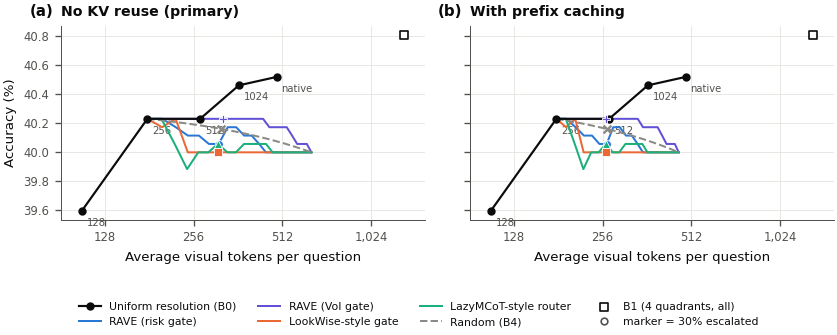

⏱ P3.G1 figure: accuracy-token frontier | wall 1.88 s | CPU 1.77 s (0.94 cores, sys 10.7%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.81/7 h
figure -> /content/rave_work/figures/fig2_effect_sizes.pdf


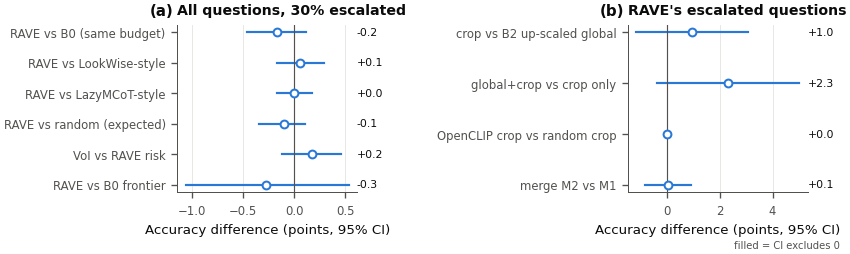

⏱ P3.G2 figure: effect sizes | wall 0.94 s | CPU 0.94 s (1.01 cores, sys 9.3%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.81/7 h
figure -> /content/rave_work/figures/fig3_where_crops_help.pdf


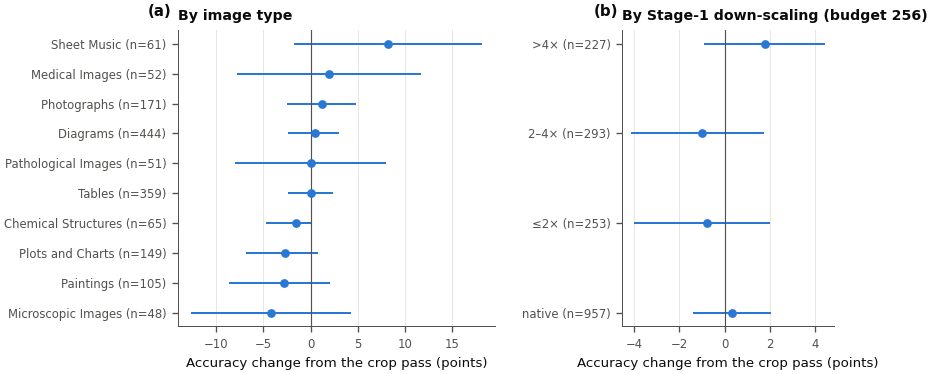

⏱ P3.G3 figure: where a crop helps | wall 1.60 s | CPU 5.88 s (3.68 cores, sys 33.1%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.81/7 h
figure -> /content/rave_work/figures/fig4_compute_and_time.pdf


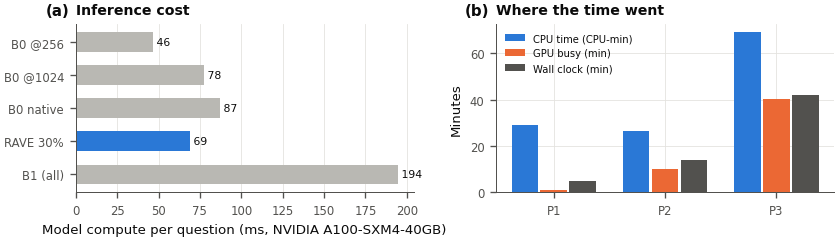

⏱ P3.G4 figure: compute and time | wall 1.08 s | CPU 1.08 s (1.01 cores, sys 9.1%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.81/7 h
figure -> /content/rave_work/figures/fig5_qualitative_examples.pdf


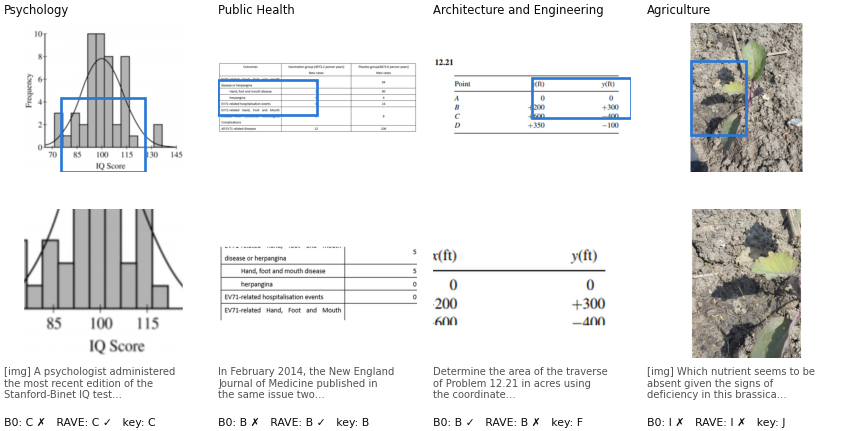

⏱ P3.G5 figure: qualitative examples | wall 1.93 s | CPU 1.94 s (1.0 cores, sys 8.6%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.81/7 h
figure -> /content/rave_work/figures/fig6_merge_weight.pdf


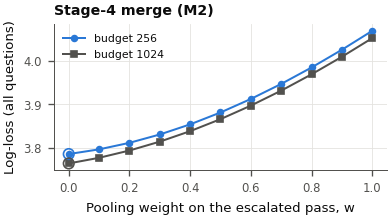

⏱ P3.G6 figure: merge weight | wall 0.50 s | CPU 0.51 s (1.01 cores, sys 8.3%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.81/7 h
⏱ cell 15: import textwrap | wall 7.99 s | CPU 12.32 s (1.54 cores, sys 11.8%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.45 kJ, peak 17.54 GB | RAM peak 8 GB | A100 time 0.81/7 h


In [17]:
import textwrap
import matplotlib.patches as mpatches
from PIL import ImageOps

POLS = ["RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT", "B4_random"]

with Phase("P3.G1 figure: accuracy-token frontier", budget_min=2):
    fig, axs = plt.subplots(1, 2, figsize=(COL2, 2.7), sharey=True)
    for ax, key, title, lt in ((axs[0], "tok", "No KV reuse (primary)", "a"), (axs[1], "tok_pc", "With prefix caching", "b")):
        ax.plot(FRONT.tok, 100 * FRONT.acc, color=COLORS["B0"], marker="o", ms=4, lw=1.3, label=NAMES["B0"], zorder=4)
        for r_ in FRONT.itertuples():
            ax.annotate(str(r_.base), (r_.tok, 100 * r_.acc), xytext=(3, -9), textcoords="offset points",
                        fontsize=6, color=INK2)
        for name in POLS:
            cv = CURVES[(CURVES.base == B) & (CURVES.policy == name)].sort_values("rate")
            ls = "--" if name == "B4_random" else "-"
            ax.plot(cv[key], 100 * cv.acc, color=COLORS[name], lw=1.2, ls=ls, label=NAMES[name], zorder=3)
            op = cv[cv.rate == MAIN_RATE]
            if MARKERS[name]:
                edge = {} if MARKERS[name] in ("x", "+") else dict(edgecolor="white", linewidth=0.5)
                ax.scatter(op[key], 100 * op.acc, color=COLORS[name], marker=MARKERS[name], s=22, zorder=5, **edge)
        if have("b1_grid4"):
            x1 = RES[B]["b1_grid4"]["vis"].mean()
            ax.scatter([x1], [100 * MERGE[B]["b1_grid4"]["M1"].mean()], marker="s", s=24, color="white",
                       edgecolor=INK, linewidth=1.0, zorder=5, label="B1 (4 quadrants, all)")
        allx = np.r_[FRONT.tok.values, CURVES[(CURVES.base == B) & CURVES.policy.isin(POLS)][key].values,
                     [RES[B]["b1_grid4"]["vis"].mean()] if have("b1_grid4") else []]
        token_axis(ax, allx.min(), allx.max())
        ax.set_xlabel("Average visual tokens per question")
        ax.set_title(title)
        panel(ax, lt)
    axs[0].set_ylabel("Accuracy (%)")
    h, l = axs[0].get_legend_handles_labels()
    h.append(Line2D([], [], color=INK2, marker="o", ls="", ms=4, markerfacecolor="white"))
    l.append(f"marker = {int(MAIN_RATE * 100)}% escalated")
    fig.legend(h, l, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08), fontsize=6.5)
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    save_fig(fig, "fig1_accuracy_token_frontier")

with Phase("P3.G2 figure: effect sizes", budget_min=2):
    pol_rows = [("H0", "RAVE vs B0 (same budget)"), ("H1", "RAVE vs LookWise-style"), ("H5", "RAVE vs LazyMCoT-style"),
                ("H2", "RAVE vs random (expected)"), ("H6", "VoI vs RAVE risk"), ("H7", "RAVE vs B0 frontier")]
    abl_rows = [("H3", "crop vs B2 up-scaled global"), ("H4", "global+crop vs crop only"),
                ("H9a", "OpenCLIP crop vs random crop"), ("H9b", "merge M2 vs M1")]
    fig, axs = plt.subplots(1, 2, figsize=(COL2, 2.2))
    for ax, rows_, title, lt in ((axs[0], pol_rows, f"All questions, {int(MAIN_RATE * 100)}% escalated", "a"),
                                 (axs[1], abl_rows, "RAVE's escalated questions", "b")):
        rows_ = [(h, lab) for h, lab in rows_ if h in TESTS]
        ys = np.arange(len(rows_))[::-1]
        for yv, (h, lab) in zip(ys, rows_):
            t_ = TESTS[h]
            sig = t_["ci_lo"] > 0
            ax.plot([t_["ci_lo"], t_["ci_hi"]], [yv, yv], color=COLORS["RAVE_risk"], lw=1.3)
            ax.scatter([t_["diff_pts"]], [yv], s=22, zorder=3, color=COLORS["RAVE_risk"] if sig else "white",
                       edgecolor=COLORS["RAVE_risk"], linewidth=1.2)
            ax.text(1.0, yv, f"{t_['diff_pts']:+.1f}", transform=ax.get_yaxis_transform(), ha="left", va="center",
                    fontsize=6.5, color=INK)
        ax.axvline(0, color=INK2, lw=0.7)
        ax.set_yticks(ys, [lab for _, lab in rows_])
        ax.set_xlabel("Accuracy difference (points, 95% CI)")
        ax.set_title(title)
        ax.grid(axis="y", visible=False)
        panel(ax, lt)
    fig.text(0.99, 0.01, "filled = CI excludes 0", ha="right", fontsize=6, color=INK2)
    fig.tight_layout(w_pad=4)
    save_fig(fig, "fig2_effect_sizes")

with Phase("P3.G3 figure: where a crop helps", budget_min=2):
    gn = gain(B, "joint_top1", "M1")            # raw effect of the crop pass, every question
    qinfo = Q.assign(ds=np.log2((Q.native_tokens_q / Q[f"g{B}_tokens_q"]).clip(lower=1)))
    rows_t = []
    for t in TOP_TYPES:
        sel = qinfo.img_type.map(lambda s_: t in json.loads(s_)).values
        if sel.sum() >= 5:
            m_, lo_, hi_ = boot_ci_fast(gn[sel])
            rows_t.append((t, int(sel.sum()), 100 * m_, 100 * lo_, 100 * hi_))
    bins = [(-0.01, 0.01, "native"), (0.01, 1, "≤2×"), (1, 2, "2–4×"), (2, 99, ">4×")]
    rows_d = []
    for lo_b, hi_b, lab in bins:
        sel = ((qinfo.ds > lo_b) & (qinfo.ds <= hi_b)).values
        if sel.sum() >= 5:
            m_, lo_, hi_ = boot_ci_fast(gn[sel])
            rows_d.append((lab, int(sel.sum()), 100 * m_, 100 * lo_, 100 * hi_))
    fig, axs = plt.subplots(1, 2, figsize=(COL2, 0.24 * max(len(rows_t), 4) + 0.9),
                            gridspec_kw=dict(width_ratios=[1.5, 1]))
    for ax, rows_, title, lt, xl in ((axs[0], sorted(rows_t, key=lambda r: r[2]), "By image type", "a", None),
                                     (axs[1], rows_d, f"By Stage-1 down-scaling (budget {B})", "b", None)):
        ys = np.arange(len(rows_))
        for yv, (lab, n_, m_, lo_, hi_) in zip(ys, rows_):
            ax.plot([lo_, hi_], [yv, yv], color=COLORS["RAVE_risk"], lw=1.2)
            ax.scatter([m_], [yv], s=18, color=COLORS["RAVE_risk"], zorder=3)
        ax.set_yticks(ys, [f"{textwrap.shorten(lab, 24, placeholder='…')} (n={n_})" for lab, n_, *_ in rows_])
        ax.axvline(0, color=INK2, lw=0.7)
        ax.set_xlabel("Accuracy change from the crop pass (points)")
        ax.set_title(title); ax.grid(axis="y", visible=False)
        panel(ax, lt)
    fig.tight_layout(w_pad=2)
    save_fig(fig, "fig3_where_crops_help")

with Phase("P3.G4 figure: compute and time", budget_min=2):
    meth = [(f"B0 @{MAIN_BASE}", RES[B]["global"]["gpu"].mean(), "#b9b8b3")]
    a1024 = aligned(B0[PROTOCOL_BASE]); anat = aligned(B0["native"])
    meth += [(f"B0 @{PROTOCOL_BASE}", a1024.gpu_s.mean(), "#b9b8b3"), ("B0 native", anat.gpu_s.mean(), "#b9b8b3"),
             (f"RAVE {int(MAIN_RATE * 100)}%", policy(B, E)["comp"].mean(), COLORS["RAVE_risk"])]
    if have("b1_grid4"):
        meth.append(("B1 (all)", RES[B]["b1_grid4"]["gpu"].mean(), "#b9b8b3"))
    led = pd.read_json(LEDGER, lines=True)
    led = led[led.kind == "phase"]
    port = []
    for nb_ in ["P1", "P2", "P3"]:
        x_ = led[led.notebook == nb_]
        if len(x_):
            port.append((nb_, x_.cpu_s.sum() / 60, x_[x_.gpu_busy_src.isin(["cuda_events", "nvml_util"])].gpu_busy_s.sum() / 60,
                         x_.wall_s.sum() / 60))
    fig, axs = plt.subplots(1, 2, figsize=(COL2, 2.2))
    ax = axs[0]
    ax.barh(np.arange(len(meth))[::-1], [1000 * m[1] for m in meth], color=[m[2] for m in meth], height=0.6)
    for yv, m in zip(np.arange(len(meth))[::-1], meth):
        ax.text(1000 * m[1], yv, f" {1000 * m[1]:.0f}", va="center", fontsize=6.5, color=INK)
    ax.set_yticks(np.arange(len(meth))[::-1], [m[0] for m in meth])
    ax.set_xlabel(f"Model compute per question (ms, {GPU_NAME or DEVICE})")
    ax.set_title("Inference cost"); ax.grid(axis="y", visible=False)
    panel(ax, "a")
    ax = axs[1]
    xs = np.arange(len(port)); bw = 0.26
    for i, (lab, col) in enumerate((("CPU time (CPU-min)", COLORS["RAVE_risk"]), ("GPU busy (min)", COLORS["LookWise_conf"]),
                                    ("Wall clock (min)", INK2))):
        vals = [p_[i + 1] for p_ in port]
        ax.bar(xs + (i - 1) * bw, vals, width=bw * 0.92, color=col, label=lab)
    ax.set_xticks(xs, [p_[0] for p_ in port])
    ax.set_ylabel("Minutes")
    ax.set_title("Where the time went")
    ax.legend(fontsize=6, loc="upper left")
    panel(ax, "b")
    fig.tight_layout(w_pad=2)
    save_fig(fig, "fig4_compute_and_time")

with Phase("P3.G5 figure: qualitative examples", budget_min=2):
    c_m2 = MERGE[B]["joint_top1"]["M2"]
    fixed = np.where(E & (g0 == 0) & (c_m2 == 1))[0]
    broke = np.where(E & (g0 == 1) & (c_m2 == 0))[0]
    pick = list(fixed[:3]) + list(broke[:1])
    if len(pick) < 4:
        pick += [i for i in np.where(E)[0] if i not in pick][:4 - len(pick)]
    if not pick:
        print("no escalated questions to show")
    else:
        t1i = SEL[SEL.role == "top1"].set_index("qid")
        rawp = IMG.set_index(["qid", "k"]).raw_path.to_dict()
        def letterbox(im, cw, ch):
            sc = min(cw / im.size[0], ch / im.size[1])
            w_, h_ = max(1, int(im.size[0] * sc)), max(1, int(im.size[1] * sc))
            cv_ = Image.new("RGB", (cw, ch), (255, 255, 255))
            ox, oy = (cw - w_) // 2, (ch - h_) // 2
            cv_.paste(im.resize((w_, h_), Image.LANCZOS), (ox, oy))
            return cv_, sc, ox, oy
        PgB, PeB = RES[B]["global"]["P"], RES[B]["joint_top1"]["P"]
        fig, axs = plt.subplots(2, len(pick), figsize=(COL2, 3.9), squeeze=False,
                                gridspec_kw=dict(height_ratios=[1.2, 1], hspace=0.12, wspace=0.08))
        for j, i in enumerate(pick):
            r_ = Q.iloc[i]; c1 = t1i.loc[r_.qid]
            with Image.open(_abs(rawp[(r_.qid, int(c1.k))])) as im0:
                im = ImageOps.exif_transpose(im0).convert("RGB")
            disp, sc, ox, oy = letterbox(im, 800, 600)
            ax = axs[0, j]; ax.imshow(disp); ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)
            ax.add_patch(mpatches.Rectangle((ox + c1.x0 * sc, oy + c1.y0 * sc), (c1.x1 - c1.x0) * sc,
                                            (c1.y1 - c1.y0) * sc, fill=False, ec=COLORS["RAVE_risk"], lw=1.6))
            ax.set_xlim(-0.5, 799.5); ax.set_ylim(599.5, -0.5)
            ax.set_title(textwrap.shorten(r_.subject.replace("_", " "), 28, placeholder="…"), fontsize=7,
                         fontweight="normal", loc="left")
            ax2 = axs[1, j]
            ax2.imshow(letterbox(Image.open(_abs(c1.crop_path)).convert("RGB"), 600, 450)[0])
            ax2.set_xticks([]); ax2.set_yticks([])
            for sp in ax2.spines.values():
                sp.set_visible(False)
            w_i = MERGE[B]["joint_top1"]["w"][int(folds[i])]
            z = (1 - w_i) * np.log(np.clip(PgB[i], 1e-12, 1)) + w_i * np.log(np.clip(PeB[i], 1e-12, 1))
            z[~VALID[i]] = -np.inf
            pf = int(np.argmax(z))
            q_txt = textwrap.shorten(PH.sub("[img]", r_.question), 90, placeholder="…")
            ok = lambda c: "✓" if c else "✗"
            ax2.text(0, -0.06, "\n".join(textwrap.wrap(q_txt, 34)[:3]), transform=ax2.transAxes, va="top", ha="left",
                     fontsize=6, color=INK2)
            ax2.text(0, -0.40, f"B0: {LETTERS[int(PgB[i].argmax())]} {ok(g0[i])}   RAVE: {LETTERS[pf]} {ok(c_m2[i])}"
                               f"   key: {LETTERS[ans[i]]}", transform=ax2.transAxes, va="top", ha="left", fontsize=6.5,
                     color=INK)
        fig.subplots_adjust(left=0.01, right=0.99, top=0.95, bottom=0.2)
        save_fig(fig, "fig5_qualitative_examples")

with Phase("P3.G6 figure: merge weight", budget_min=1):
    fig, ax = plt.subplots(figsize=(COL1, 2.0))
    for base, col, mk in ((MAIN_BASE, COLORS["RAVE_risk"], "o"), (PROTOCOL_BASE, INK2, "s")):
        if base not in ANALYSIS_BASES:
            continue
        nl = MERGE[base]["joint_top1"]["nll"]
        ax.plot(W_GRID, nl, color=col, marker=mk, ms=3.5, lw=1.2, label=f"budget {base}")
        ax.scatter([W_GRID[int(np.nanargmin(nl))]], [np.nanmin(nl)], s=40, facecolor="none", edgecolor=col, zorder=4)
    ax.set_xlabel("Pooling weight on the escalated pass, w")
    ax.set_ylabel("Log-loss (all questions)")
    ax.set_title("Stage-4 merge (M2)")
    ax.legend(fontsize=6.5)
    fig.tight_layout()
    save_fig(fig, "fig6_merge_weight")

## Summary — results, CPU/GPU time of Portion 3 and of the whole 7-hour window

In [18]:
summary = dict(model=MODEL_ID, n_questions=N, main_base=B, main_rate=MAIN_RATE, passes_done=list(DONE),
               passes_skipped=SKIPPED, b0_acc=float(g0.mean()), rave_acc=float(c_rave.mean()),
               tests={k: {kk: vv for kk, vv in v.items() if kk in ("diff_pts", "ci_lo", "ci_hi", "p_boot", "p_holm",
                                                                    "reject_holm", "holds")} for k, v in TESTS.items()},
               figures=sorted(p.name for p in FIG_DIR.glob("*.pdf")),
               tables=sorted(p.name for p in DIRS["preds"].glob("table_*.tex")))
(DIRS["logs"] / "results_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print(json.dumps({k: summary[k] for k in ("b0_acc", "rave_acc", "passes_skipped")}, default=float))
window("end of Portion 3")
time_report("P3")
print()
time_report()            # every portion: total CPU, GPU and wall time
sync_to_drive(quiet=False)
save_notebook_copy("RAVE_v4_P3_GPU_escalation_results")

{"b0_acc": 0.4023121387283237, "rave_acc": 0.4005780346820809, "passes_skipped": []}
⏱ A100 time end of Portion 3: 0.81 h used, 6.19 h left of 7 h (P2–P4 cells)
[P3] 15 cells | wall 43.2 min | CPU 69.6 CPU-min (1.6 cores avg) | GPU busy 40.43 min (phases) / 39.17 min (cells, NVML) | GPU energy 938.3 kJ | A100 time used (P2–P4) 0.81 h of 7

[all notebooks] 54 cells | wall 58.7 min | CPU 114.1 CPU-min (1.9 cores avg) | GPU busy 51.36 min (phases) / 44.71 min (cells, NVML) | GPU energy 1093.5 kJ | A100 time used (P2–P4) 0.81 h of 7
Drive sync: 1 file(s) -> /content/drive/MyDrive/Koushik 2/rave_work
notebook with outputs -> /content/drive/MyDrive/Koushik 2/notebooks/RAVE_v4_P3_GPU_escalation_results_executed_20261018_1418.ipynb
⏱ cell 16: summary = dict(model=MODEL_ID, n_questions=N, main_base=B, m | wall 2.23 s | CPU 0.08 s (0.04 cores, sys 2.1%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.12 kJ, peak 17.54 GB | RAM peak 8 GB | A100 time 0.81/7 h
